# Tiền xử lý dữ liệu bảng: Adult Census Income

Chương này cài đặt và so sánh có kiểm soát sáu nhóm kỹ thuật tiền xử lý. Mỗi lựa chọn đều dựa trên phát hiện từ chương EDA và được kiểm chứng bằng số liệu:

1. Điền giá trị thiếu có kiểm soát (5 chiến lược, đo RMSE).
2. Phát hiện và xử lý ngoại lai (4 nhóm phương pháp, Jaccard, KS test).
3. Chuẩn hóa (4 phương pháp, violin plot, Levene test).
4. Mã hóa biến phân loại nâng cao (Target, Binary, Frequency; đo VIF và explained variance).
5. Chọn đặc trưng và giảm chiều (filter, model-based, PCA, t-SNE, UMAP; F1 theo số đặc trưng).
6. [Nâng cao] Xử lý mất cân bằng lớp (SMOTE, ADASYN, Random Under-sampling).

**Nguyên tắc chống rò rỉ dữ liệu (data leakage):** dữ liệu được chia train/test **ngay từ đầu**. Mọi tham số của phép biến đổi (trung bình, IQR, bảng mã hóa, mô hình điền giá trị thiếu, v.v.) chỉ được ước lượng trên tập train rồi áp dụng lại cho tập test. Tập test chỉ dùng để đánh giá cuối cùng.

In [ ]:
import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="Graph is not fully connected")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from imblearn.over_sampling import ADASYN, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import DBSCAN
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import (GradientBoostingClassifier, HistGradientBoostingClassifier,
                              IsolationForest, RandomForestClassifier)
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (bật IterativeImputer)
from sklearn.feature_selection import RFECV, chi2, f_classif, mutual_info_classif
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier, LocalOutlierFactor, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   QuantileTransformer, RobustScaler, StandardScaler, TargetEncoder)

from utils.config import PROCESSED_DIR, RANDOM_STATE, set_seed
from utils.data_loader import load_adult

set_seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

ALPHA = 0.05
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 0. Chuẩn bị dữ liệu

Các bước dưới đây là những quyết định đã có căn cứ từ chương EDA. Chúng mang tính tất định (không học tham số từ dữ liệu), nên có thể làm trước khi chia train/test:

- Đổi `?` thành `NaN`, loại 24 dòng trùng lặp.
- Loại `education` vì trùng thông tin hoàn toàn với `education.num`.
- Với 7 người `Never-worked`, nghề nghiệp không tồn tại chứ không phải bị thiếu, nên gán `occupation = "None"`.
- Mã hóa nhãn: `income` bằng 1 nếu `>50K`, bằng 0 nếu ngược lại.

Sau đó chia **80% train / 20% test có phân tầng theo nhãn**, giữ đúng tỷ lệ 76/24 ở cả hai tập.

In [ ]:
raw = load_adult().replace("?", np.nan)
n_raw = len(raw)
df = raw.drop_duplicates().drop(columns="education").reset_index(drop=True)
n_dropped_dup = n_raw - len(df)

never_worked = df["workclass"].eq("Never-worked") & df["occupation"].isna()
df.loc[never_worked, "occupation"] = "None"
df["income"] = (df["income"] == ">50K").astype(int)

NUM_COLS = ["age", "fnlwgt", "education.num", "capital.gain", "capital.loss", "hours.per.week"]
CAT_COLS = ["workclass", "marital.status", "occupation", "relationship", "race", "sex", "native.country"]
CAT_MISSING = ["workclass", "occupation", "native.country"]
COMPLETE_CATS = [c for c in CAT_COLS if c not in CAT_MISSING]
df[CAT_COLS] = df[CAT_COLS].astype(object)

X = df[NUM_COLS + CAT_COLS]
y = df["income"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_test = X_train.reset_index(drop=True), X_test.reset_index(drop=True)
y_train, y_test = y_train.reset_index(drop=True), y_test.reset_index(drop=True)

print(f"Đã loại {n_dropped_dup} dòng trùng lặp; gán occupation='None' cho {int(never_worked.sum())} người Never-worked")
print(f"Train: {X_train.shape}, tỷ lệ >50K = {y_train.mean():.4f}")
print(f"Test : {X_test.shape}, tỷ lệ >50K = {y_test.mean():.4f}")
print("Số ô thiếu trên train:", X_train[CAT_MISSING].isna().sum().to_dict())

Đã loại 24 dòng trùng lặp; gán occupation='None' cho 7 người Never-worked
Train: (26029, 13), tỷ lệ >50K = 0.2409
Test : (6508, 13), tỷ lệ >50K = 0.2409
Số ô thiếu trên train: {'workclass': 1472, 'occupation': 1472, 'native.country': 469}


## 1. Điền giá trị thiếu có kiểm soát

### Lý thuyết

Gọi $x_{ij}$ là giá trị thiếu của thuộc tính $j$ tại dòng $i$, và $O_j$ là tập các dòng quan sát được của thuộc tính $j$.

| Chiến lược | Giá trị điền $\hat{x}_{ij}$ | Đặc điểm |
|---|---|---|
| **Mean** | $\bar{x}_j = \frac{1}{\lvert O_j \rvert}\sum_{k \in O_j} x_{kj}$ | Bảo toàn trung bình, làm giảm phương sai, nhạy với ngoại lai |
| **Median** | $\operatorname{median}\{x_{kj} : k \in O_j\}$ | Bền vững với ngoại lai và phân phối lệch |
| **Mode** | giá trị xuất hiện nhiều nhất trong $O_j$ | Phù hợp với biến rời rạc hoặc phân loại |
| **k-NN** | $\frac{1}{k}\sum_{l \in N_k(i)} x_{lj}$ | $N_k(i)$ là $k$ láng giềng gần nhất của dòng $i$ theo khoảng cách trên các cột quan sát được |
| **MICE** | Hồi quy lặp: $x_j \approx f_j(x_{-j})$ | Mỗi cột có giá trị thiếu được hồi quy theo các cột còn lại, lặp nhiều vòng tới khi hội tụ |

Khoảng cách dùng cho k-NN là `nan_euclidean`. Khoảng cách chỉ tính trên các tọa độ cả hai dòng cùng có, rồi nhân tỷ lệ bù lại số tọa độ bị bỏ qua:

$$d(a, b) = \sqrt{\frac{p}{\lvert P_{ab} \rvert}\sum_{t \in P_{ab}} (a_t - b_t)^2},$$

với $p$ là tổng số tọa độ và $P_{ab}$ là tập tọa độ mà cả $a$ và $b$ đều quan sát được.

**MICE** (Multivariate Imputation by Chained Equations): khởi tạo bằng mean, rồi lần lượt với từng cột $j$, huấn luyện một mô hình hồi quy (ở đây là Bayesian Ridge) dự đoán $x_j$ từ các cột còn lại trên những dòng có $x_j$, sau đó dùng mô hình để cập nhật các ô thiếu của $x_j$. Lặp tới khi các giá trị điền ổn định.

### Thiết kế thí nghiệm

Dữ liệu thiếu thật của Adult chỉ nằm ở biến phân loại, và ta không biết giá trị đúng của chúng. Để **đo được sai số**, ta tạo thêm giá trị thiếu nhân tạo ở những ô *đã biết giá trị thật*:

1. **Thí nghiệm A (biến số):** trên tập train, xóa ngẫu nhiên 10% số ô của 6 cột số theo cơ chế MCAR. Ngữ cảnh cho kNN và MICE gồm 6 cột số (đã chuẩn hóa Z-score) cùng One-Hot của 4 cột phân loại đầy đủ.
2. Điền lại bằng 7 cấu hình (mean, median, mode, kNN với $k \in \{3, 5, 10\}$, MICE), rồi tính sai số **chỉ trên các ô bị xóa** $M$:

$$\text{RMSE}_j = \sqrt{\frac{1}{\lvert M_j \rvert}\sum_{i \in M_j}\left(\hat{x}_{ij} - x_{ij}\right)^2}, \qquad \text{NRMSE}_j = \frac{\text{RMSE}_j}{\sigma_j}.$$

   NRMSE không có đơn vị, nên lấy trung bình được qua các cột. Điền bằng mean cho $\text{NRMSE} \approx 1$, nên mọi phương pháp tốt phải cho giá trị **nhỏ hơn 1**.
3. Ngoài RMSE, đo thêm **tỷ lệ phương sai** $\operatorname{Var}(\hat{x}) / \operatorname{Var}(x)$ trên các ô bị xóa, để xem phương pháp có làm "co" phân phối hay không.
4. Lặp lại 3 lần với 3 seed khác nhau và báo cáo trung bình.
5. **Thí nghiệm B (biến phân loại):** với 3 cột có giá trị thiếu thật, xóa thêm 10% số giá trị đã biết rồi so sánh **accuracy** của Mode với bộ phân loại kNN.

In [ ]:
N_REPS = 3
MISSING_RATE = 0.10

ctx_transformer = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COMPLETE_CATS),
])
M_full = ctx_transformer.fit_transform(X_train)
n_num = len(NUM_COLS)
num_sigma = X_train[NUM_COLS].std(ddof=0).to_numpy()

imputers = {
    "Mean": lambda: SimpleImputer(strategy="mean"),
    "Median": lambda: SimpleImputer(strategy="median"),
    "Mode": lambda: SimpleImputer(strategy="most_frequent"),
    "kNN (k=3)": lambda: KNNImputer(n_neighbors=3),
    "kNN (k=5)": lambda: KNNImputer(n_neighbors=5),
    "kNN (k=10)": lambda: KNNImputer(n_neighbors=10),
    "MICE": lambda: IterativeImputer(max_iter=10, random_state=RANDOM_STATE),
}

imp_records = []
for rep in range(N_REPS):
    rng = np.random.default_rng(RANDOM_STATE + rep)
    mask = rng.random((len(M_full), n_num)) < MISSING_RATE
    M_missing = M_full.copy()
    M_missing[:, :n_num] = np.where(mask, np.nan, M_full[:, :n_num])
    for name, make_imputer in imputers.items():
        t0 = time.perf_counter()
        M_hat = make_imputer().fit_transform(M_missing)
        elapsed = time.perf_counter() - t0
        for j, col in enumerate(NUM_COLS):
            true_vals, imp_vals = M_full[mask[:, j], j], M_hat[mask[:, j], j]
            nrmse = float(np.sqrt(np.mean((imp_vals - true_vals) ** 2)))  # dữ liệu đã chuẩn hóa nên RMSE = NRMSE
            imp_records.append({"rep": rep, "chiến lược": name, "thuộc tính": col,
                                "RMSE": nrmse * num_sigma[j], "NRMSE": nrmse,
                                "tỷ lệ phương sai": np.var(imp_vals) / np.var(true_vals),
                                "thời gian (s)": elapsed})
imp_results = pd.DataFrame(imp_records)
print(f"Mỗi lần lặp xóa {mask.sum():,} ô ({mask.mean():.2%} số ô của 6 cột số)")

Mỗi lần lặp xóa 15,858 ô (10.15% số ô của 6 cột số)


In [ ]:
rmse_table = imp_results.pivot_table(index="chiến lược", columns="thuộc tính", values="RMSE", aggfunc="mean")[NUM_COLS]
summary_cols = imp_results.groupby(["chiến lược", "rep"]).agg(
    NRMSE=("NRMSE", "mean"), var_ratio=("tỷ lệ phương sai", "mean"), time=("thời gian (s)", "first"))
imputation_summary = summary_cols.groupby("chiến lược").agg(
    **{"NRMSE TB": ("NRMSE", "mean"), "NRMSE độ lệch chuẩn": ("NRMSE", "std"),
       "tỷ lệ phương sai TB": ("var_ratio", "mean"), "thời gian (s)": ("time", "mean")})
imputation_table = rmse_table.join(imputation_summary).sort_values("NRMSE TB")
best_num_imputer = imputation_table.index[0]
print("Chiến lược điền biến số tốt nhất theo NRMSE trung bình:", best_num_imputer)
imputation_table

Chiến lược điền biến số tốt nhất theo NRMSE trung bình: MICE


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,NRMSE TB,NRMSE độ lệch chuẩn,tỷ lệ phương sai TB,thời gian (s)
chiến lược,,,,,,,,,,
MICE,10.8431,"103,381.0811",2.4763,"7,388.6876",402.9502,11.4305,0.9410,0.0141,0.1133,2.8524
kNN (k=10),11.1984,"109,404.2019",2.5482,"7,875.9661",425.0666,11.6438,0.9824,0.0057,0.2051,21.8549
Mean,13.6606,"104,763.9334",2.5681,"7,495.1685",406.8806,12.2289,0.9984,0.0159,0.0000,0.0134
Median,13.7884,"105,575.9885",2.5670,"7,575.2827",416.7429,12.2422,1.0072,0.0167,0.0000,0.0356
kNN (k=5),11.6696,"115,234.7205",2.6462,"8,439.0764",445.2527,12.2811,1.0331,0.0078,0.3221,21.6600
Mode,15.4433,"133,155.4517",2.7599,"7,575.2827",416.7429,12.2422,1.0834,0.0418,0.0000,0.0188
kNN (k=3),12.2753,"121,895.7560",2.8005,"9,306.1519",471.6190,13.1003,1.1023,0.0258,0.4756,24.0454


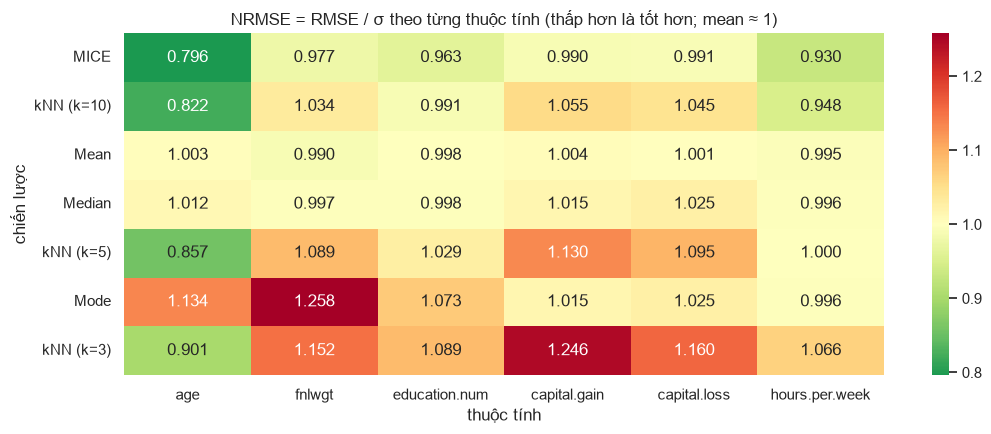

In [ ]:
nrmse_pivot = imp_results.pivot_table(index="chiến lược", columns="thuộc tính", values="NRMSE", aggfunc="mean")
nrmse_pivot = nrmse_pivot.loc[imputation_table.index, NUM_COLS]
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(nrmse_pivot, annot=True, fmt=".3f", cmap="RdYlGn_r", center=1.0, ax=ax)
ax.set_title("NRMSE = RMSE / σ theo từng thuộc tính (thấp hơn là tốt hơn; mean ≈ 1)")
plt.tight_layout()
plt.show()

### Nhận xét thí nghiệm A (biến số)

**Xếp hạng theo NRMSE trung bình:** MICE (0,941) < kNN k=10 (0,982) < Mean (0,998) < Median (1,007) < kNN k=5 (1,033) < Mode (1,083) < kNN k=3 (1,102). Độ lệch chuẩn qua 3 lần lặp chỉ khoảng 0,01, nên thứ hạng ổn định.

**MICE tốt nhất, nhưng chỉ tốt hơn Mean khoảng 6%.** Đây là hệ quả trực tiếp của chương EDA: các biến số gần như **độc lập tuyến tính** với nhau (|r| ≤ 0,17, VIF ≤ 1,04). Mọi phương pháp dựa trên quan hệ giữa các biến (MICE, kNN) chỉ có ít thông tin để khai thác. MICE thắng rõ nhất ở `age` (RMSE 10,8 năm so với 13,7 năm của Mean), vì tuổi liên hệ với `marital.status` và `relationship` qua One-Hot trong ngữ cảnh (ví dụ `Own-child` thường trẻ, `Widowed` thường lớn tuổi).

**Đánh đổi giữa thiên lệch và phương sai của kNN:** $k = 3$ **kém hơn cả Mean**. Trung bình của 3 láng giềng có phương sai cao (tỷ lệ phương sai 0,48, gần với độ phân tán thật nhất) nhưng sai số lớn. Tăng $k$ làm giảm nhiễu và NRMSE, đổi lại phân phối bị co lại nhiều hơn.

**Mean, Median, Mode có tỷ lệ phương sai bằng 0:** mọi ô thiếu nhận cùng một giá trị, làm phân phối bị co lại và tạo một cột đỉnh nhân tạo. Đây là lý do không nên dùng chúng khi tỷ lệ thiếu lớn, dù RMSE không quá tệ. MICE cũng làm co phân phối mạnh (0,11), vì nó điền bằng *kỳ vọng có điều kiện* chứ không lấy mẫu.

**Riêng `capital.gain` và `capital.loss`:** mọi phương pháp đều có NRMSE ≈ 1. Không thể dự đoán được *ai* có lãi hoặc lỗ vốn từ các biến khác, và một vài giá trị 99999 chi phối RMSE.

**Kết luận:** chọn **MICE** cho biến số. Adult không có giá trị thiếu thật ở biến số, nên lựa chọn này áp dụng khi dữ liệu mới có ô thiếu ở biến số.

In [ ]:
cat_records = []
ctx_train = M_full
for col in CAT_MISSING:
    values = X_train[col].to_numpy()
    observed = np.flatnonzero(pd.notna(values))
    for rep in range(N_REPS):
        rng = np.random.default_rng(RANDOM_STATE + rep)
        masked = rng.choice(observed, size=int(MISSING_RATE * len(observed)), replace=False)
        known = np.setdiff1d(observed, masked)
        y_known, y_true = values[known], values[masked]
        mode_value = pd.Series(y_known).mode()[0]
        cat_records.append({"thuộc tính": col, "rep": rep, "chiến lược": "Mode",
                            "accuracy": float(np.mean(y_true == mode_value))})
        for k in (3, 5, 10):
            knn = KNeighborsClassifier(n_neighbors=k).fit(ctx_train[known], y_known)
            cat_records.append({"thuộc tính": col, "rep": rep, "chiến lược": f"kNN (k={k})",
                                "accuracy": float(np.mean(knn.predict(ctx_train[masked]) == y_true))})
cat_imp_results = pd.DataFrame(cat_records)
cat_imputation_table = cat_imp_results.pivot_table(index="chiến lược", columns="thuộc tính", values="accuracy", aggfunc="mean")[CAT_MISSING]
best_cat_imputer = cat_imputation_table.idxmax().to_dict()
print("Chiến lược tốt nhất cho từng cột phân loại:", best_cat_imputer)
cat_imputation_table

Chiến lược tốt nhất cho từng cột phân loại: {'workclass': 'Mode', 'occupation': 'kNN (k=10)', 'native.country': 'kNN (k=10)'}


thuộc tính,workclass,occupation,native.country
chiến lược,,,
Mode,0.7390,0.1302,0.9195
kNN (k=10),0.7344,0.2888,0.9238
kNN (k=3),0.6706,0.2443,0.9115
kNN (k=5),0.7079,0.2637,0.9215


### Nhận xét thí nghiệm B (biến phân loại)

| Cột | Mode | kNN tốt nhất | Chọn |
|---|---|---|---|
| `workclass` | **73,9%** | 73,4% (k=10) | Mode |
| `occupation` | 13,0% | **28,9%** (k=10) | kNN, k=10 |
| `native.country` | 92,0% | **92,4%** (k=10) | kNN, k=10 |

- **`workclass`:** `Private` chiếm khoảng 74%, nên Mode đã là một dự đoán rất mạnh và kNN không vượt được.
- **`occupation`** có 15 mức phân bố khá đều (mức phổ biến nhất chỉ chiếm 13%). Đây là nơi kNN hơn Mode **2,2 lần** (28,9% so với 13,0%), vì nghề nghiệp liên hệ với học vấn, giới tính, số giờ làm, tình trạng hôn nhân.
- **`native.country`:** kNN chỉ hơn Mode 0,4 điểm phần trăm. Mức chênh này nằm trong biến động ngẫu nhiên, nhưng theo quy tắc chọn đã đặt trước thì vẫn chọn kNN.

**Lưu ý quan trọng:** thí nghiệm này xóa dữ liệu theo **MCAR**, trong khi EDA đã chỉ ra dữ liệu thiếu thật của `workclass` và `occupation` là **MAR, có thể có thêm MNAR** (người trẻ, người lớn tuổi, làm ít giờ). Độ chính xác trên dữ liệu thiếu thật có thể khác với con số đo được ở đây. Chính vì vậy ta giữ thêm biến chỉ báo `work.missing`: dù giá trị điền có sai, mô hình vẫn biết dòng đó vốn bị thiếu.

### Áp dụng cho dữ liệu thiếu thật

Mỗi cột phân loại được điền bằng chiến lược tốt nhất của nó trong thí nghiệm B. Mô hình điền chỉ được huấn luyện trên tập train rồi áp dụng cho cả train và test.

Ngoài ra, EDA cho thấy việc thiếu `workclass` và `occupation` mang thông tin: tỷ lệ thu nhập >50K là 10,4% khi thiếu, so với 24,9% khi có dữ liệu. Vì vậy ta giữ lại thông tin này bằng biến chỉ báo `work.missing` **trước khi** điền.

In [ ]:
FLAG_COLS = ["work.missing"]


def apply_categorical_imputation(X_tr: pd.DataFrame, X_te: pd.DataFrame):
    X_tr, X_te = X_tr.copy(), X_te.copy()
    for X_ in (X_tr, X_te):
        X_["work.missing"] = X_["workclass"].isna().astype(float)
    ctx_tr, ctx_te = ctx_transformer.transform(X_tr), ctx_transformer.transform(X_te)
    for col in CAT_MISSING:
        strategy = best_cat_imputer[col]
        obs = X_tr[col].notna().to_numpy()
        if strategy == "Mode":
            fill = X_tr.loc[obs, col].mode()[0]
            X_tr[col] = X_tr[col].fillna(fill)
            X_te[col] = X_te[col].fillna(fill)
        else:
            k = int(strategy.split("=")[1].rstrip(")"))
            knn = KNeighborsClassifier(n_neighbors=k).fit(ctx_tr[obs], X_tr.loc[obs, col])
            for X_, ctx_ in ((X_tr, ctx_tr), (X_te, ctx_te)):
                miss = X_[col].isna().to_numpy()
                if miss.any():
                    X_.loc[miss, col] = knn.predict(ctx_[miss])
    return X_tr, X_te


X_train_imp, X_test_imp = apply_categorical_imputation(X_train, X_test)
print("Còn ô thiếu trên train:", int(X_train_imp.isna().sum().sum()), "| trên test:", int(X_test_imp.isna().sum().sum()))
print("Tỷ lệ work.missing = 1 trên train:", round(X_train_imp["work.missing"].mean(), 4))

Còn ô thiếu trên train: 0 | trên test: 0
Tỷ lệ work.missing = 1 trên train: 0.0566


## 2. Phát hiện và xử lý ngoại lai

### Lý thuyết

**Phương pháp đơn biến** (xét từng thuộc tính riêng lẻ; một dòng là ngoại lai nếu *bất kỳ* thuộc tính nào vi phạm):

- **IQR (Tukey):** $x$ là ngoại lai nếu $x < Q_1 - 1.5\,\text{IQR}$ hoặc $x > Q_3 + 1.5\,\text{IQR}$, với $\text{IQR} = Q_3 - Q_1$.
- **Z-score:** $x$ là ngoại lai nếu $\lvert z \rvert = \left\lvert \dfrac{x - \bar{x}}{s} \right\rvert > 3$. Ngưỡng 3 tương ứng 0,27% nếu dữ liệu chuẩn, nhưng $\bar{x}$ và $s$ lại bị chính ngoại lai kéo lệch.

**Phương pháp đa biến** (xét đồng thời mọi thuộc tính), áp dụng trên không gian 6 thuộc tính số. Không gian này đã lấy $\log$ cho `fnlwgt`, $\log(1+x)$ cho `capital.*`, rồi chuẩn hóa Z-score, để các khoảng cách có ý nghĩa:

- **Isolation Forest:** ngoại lai dễ bị "cô lập" hơn, nên cần ít lần cắt ngẫu nhiên hơn. Điểm bất thường là
  $$s(x, n) = 2^{-\frac{E[h(x)]}{c(n)}},$$
  với $h(x)$ là độ sâu đường đi tới $x$ trong một cây cô lập, $c(n)$ là độ sâu trung bình để chuẩn hóa. $s$ càng gần 1 thì càng bất thường. Tham số `contamination` $\in \{0.01, 0.05, 0.1\}$ đặt tỷ lệ ngoại lai kỳ vọng.
- **LOF (Local Outlier Factor):** so sánh mật độ cục bộ của một điểm với mật độ của các láng giềng:
  $$\text{LOF}_k(x) = \frac{1}{\lvert N_k(x) \rvert}\sum_{o \in N_k(x)} \frac{\text{lrd}_k(o)}{\text{lrd}_k(x)}.$$
  $\text{LOF} \gg 1$ nghĩa là điểm nằm ở vùng thưa hơn hẳn láng giềng của nó. Ta thử `n_neighbors` $\in \{10, 20, 50\}$, ngưỡng tự động của scikit-learn.
- **DBSCAN:** điểm lõi có ít nhất `min_samples` láng giềng trong bán kính $\varepsilon$. Điểm không thuộc cụm nào (nhiễu, nhãn $-1$) được coi là ngoại lai. Ta chọn `min_samples` $= 2 \times \text{số chiều} = 12$, và chọn $\varepsilon$ tại "khuỷu" của đồ thị khoảng cách tới láng giềng thứ `min_samples`.

**So sánh các phương pháp:**

- Mức độ trùng nhau giữa hai tập ngoại lai đo bằng **Jaccard**: $J(A, B) = \dfrac{\lvert A \cap B \rvert}{\lvert A \cup B \rvert}$.
- Tác động của việc loại ngoại lai lên phân phối đo bằng **KS test hai mẫu**: $D = \sup_x \lvert F_{\text{trước}}(x) - F_{\text{sau}}(x) \rvert$.

In [ ]:
def log_space(X_: pd.DataFrame) -> pd.DataFrame:
    Z = X_[NUM_COLS].astype(float).copy()
    Z["fnlwgt"] = np.log(Z["fnlwgt"])
    Z[["capital.gain", "capital.loss"]] = np.log1p(Z[["capital.gain", "capital.loss"]])
    return Z


num_train = X_train_imp[NUM_COLS].astype(float)
O_space = StandardScaler().fit_transform(log_space(X_train_imp))

q1, q3 = num_train.quantile(0.25), num_train.quantile(0.75)
iqr = q3 - q1
iqr_flags = (num_train < q1 - 1.5 * iqr) | (num_train > q3 + 1.5 * iqr)
z_flags = ((num_train - num_train.mean()) / num_train.std()).abs() > 3

univariate_rates = pd.DataFrame({"IQR (%)": iqr_flags.mean() * 100, "Z-score (%)": z_flags.mean() * 100, "IQR": iqr})
univariate_rates

,IQR (%),Z-score (%),IQR
age,0.7530,0.3803,19.0000
fnlwgt,3.0889,1.0642,"119,218.0000"
education.num,3.6844,0.6301,3.0000
capital.gain,8.3830,0.6800,0.0000
capital.loss,4.7332,4.5680,0.0000
hours.per.week,27.3887,1.3024,5.0000


In [ ]:
outlier_masks = {"IQR": iqr_flags.any(axis=1).to_numpy(), "Z-score": z_flags.any(axis=1).to_numpy()}
timings = {}

for c in (0.01, 0.05, 0.1):
    t0 = time.perf_counter()
    iso = IsolationForest(n_estimators=200, contamination=c, random_state=RANDOM_STATE, n_jobs=-1)
    outlier_masks[f"IForest c={c}"] = iso.fit_predict(O_space) == -1
    timings[f"IForest c={c}"] = time.perf_counter() - t0

for k in (10, 20, 50):
    t0 = time.perf_counter()
    lof = LocalOutlierFactor(n_neighbors=k, n_jobs=-1)
    outlier_masks[f"LOF k={k}"] = lof.fit_predict(O_space) == -1
    timings[f"LOF k={k}"] = time.perf_counter() - t0

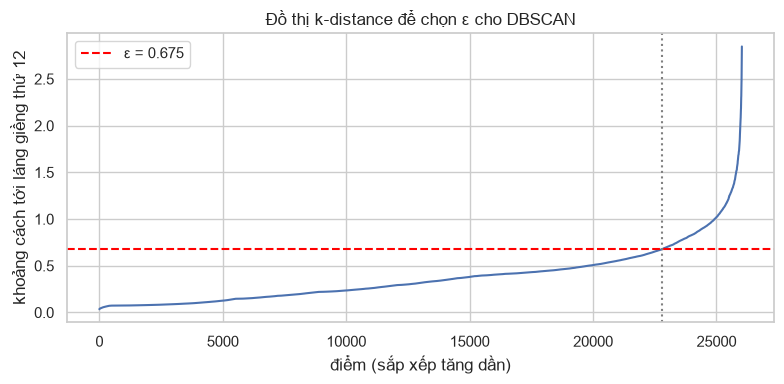

DBSCAN: eps = 0.6751, min_samples = 12, số cụm = 6


In [ ]:
DBSCAN_MIN_SAMPLES = 2 * O_space.shape[1]
knn_dist = NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES).fit(O_space).kneighbors(O_space)[0][:, -1]
k_dist_sorted = np.sort(knn_dist)

# Khuỷu: điểm xa nhất so với đường thẳng nối đầu và cuối đồ thị (sau khi chuẩn hóa hai trục về [0, 1])
xn = np.linspace(0, 1, len(k_dist_sorted))
yn = (k_dist_sorted - k_dist_sorted[0]) / (k_dist_sorted[-1] - k_dist_sorted[0])
knee_idx = int(np.argmax(xn - yn))
DBSCAN_EPS = float(k_dist_sorted[knee_idx])

t0 = time.perf_counter()
db_labels = DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES, n_jobs=-1).fit_predict(O_space)
timings["DBSCAN"] = time.perf_counter() - t0
outlier_masks["DBSCAN"] = db_labels == -1
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_dist_sorted)
ax.axhline(DBSCAN_EPS, color="red", ls="--", label=f"ε = {DBSCAN_EPS:.3f}")
ax.axvline(knee_idx, color="gray", ls=":")
ax.set(xlabel="điểm (sắp xếp tăng dần)", ylabel=f"khoảng cách tới láng giềng thứ {DBSCAN_MIN_SAMPLES}",
       title="Đồ thị k-distance để chọn ε cho DBSCAN")
ax.legend()
plt.tight_layout()
plt.show()
print(f"DBSCAN: eps = {DBSCAN_EPS:.4f}, min_samples = {DBSCAN_MIN_SAMPLES}, số cụm = {n_clusters}")

In [ ]:
cap_max_rows = (X_train_imp["capital.gain"] == 99_999).to_numpy()
outlier_summary = pd.DataFrame({
    "số ngoại lai": {m: int(v.sum()) for m, v in outlier_masks.items()},
    "tỷ lệ phát hiện (%)": {m: v.mean() * 100 for m, v in outlier_masks.items()},
    "% ngoại lai có income >50K": {m: y_train[v].mean() * 100 for m, v in outlier_masks.items()},
    "bắt được bao nhiêu % dòng gain=99999": {m: v[cap_max_rows].mean() * 100 for m, v in outlier_masks.items()},
})
print(f"Tỷ lệ >50K trên toàn tập train: {y_train.mean():.2%}")
outlier_summary

Tỷ lệ >50K trên toàn tập train: 24.09%


,số ngoại lai,tỷ lệ phát hiện (%),% ngoại lai có income >50K,bắt được bao nhiêu % dòng gain=99999
IQR,10804,41.5075,28.4061,100.0000
Z-score,2180,8.3753,44.5872,100.0000
IForest c=0.01,261,1.0027,51.7241,13.0769
IForest c=0.05,1302,5.0021,50.9985,57.6923
IForest c=0.1,2603,10.0004,49.2893,93.0769
LOF k=10,911,3.4999,18.3315,13.8462
LOF k=20,772,2.9659,18.2642,15.3846
LOF k=50,765,2.9390,20.3922,10.7692
DBSCAN,1843,7.0806,39.0667,95.3846


### Nhận xét tỷ lệ phát hiện

- **IQR đánh dấu 41,5% số dòng là ngoại lai, nên không dùng được.** Nguyên nhân đã được dự báo từ EDA: `hours.per.week` có IQR chỉ bằng 5 (27,4% dòng vượt ngưỡng), còn `capital.*` có IQR bằng 0, nên **mọi giá trị khác 0** đều bị coi là ngoại lai (8,4% và 4,7%).
- **Z-score (8,4%)** ít cực đoan hơn, nhưng vẫn đánh dấu 4,6% dòng vì `capital.loss`: mọi khoản lỗ vốn khác 0 đều vượt $3\sigma$, do $\sigma$ bị khối giá trị 0 ép nhỏ.
- **Isolation Forest** cho đúng tỷ lệ `contamination` đã đặt (1%, 5%, 10%), vì tham số này chính là ngưỡng cắt.
- **LOF** (khoảng 3%) và **DBSCAN** (7,1%, với $\varepsilon = 0.675$ và 6 cụm) tự xác định tỷ lệ.

**Ngoại lai có phải là "lỗi" không?**

- Với IForest và Z-score, khoảng **50% số ngoại lai có thu nhập >50K**, gấp đôi tỷ lệ chung (24,1%). Các điểm "bất thường" này chủ yếu là **người có thu nhập từ vốn**, tức đúng nhóm mà bài toán cần nhận diện.
- IQR, Z-score, DBSCAN (95%) và IForest c=0,1 (93%) bắt được gần hết 130 dòng `capital.gain = 99999`.
- **LOF lại khác hẳn:** chỉ bắt 11–15% các dòng 99999, và ngoại lai của LOF có tỷ lệ >50K chỉ 18–20%, *thấp hơn* tỷ lệ chung. LOF là phương pháp **cục bộ**: điểm 99999 có hàng trăm "đồng loại" nên mật độ cục bộ không thấp. LOF tìm những tổ hợp giá trị hiếm nằm *giữa* các vùng dữ liệu dày, phần lớn thuộc lớp `≤50K`.

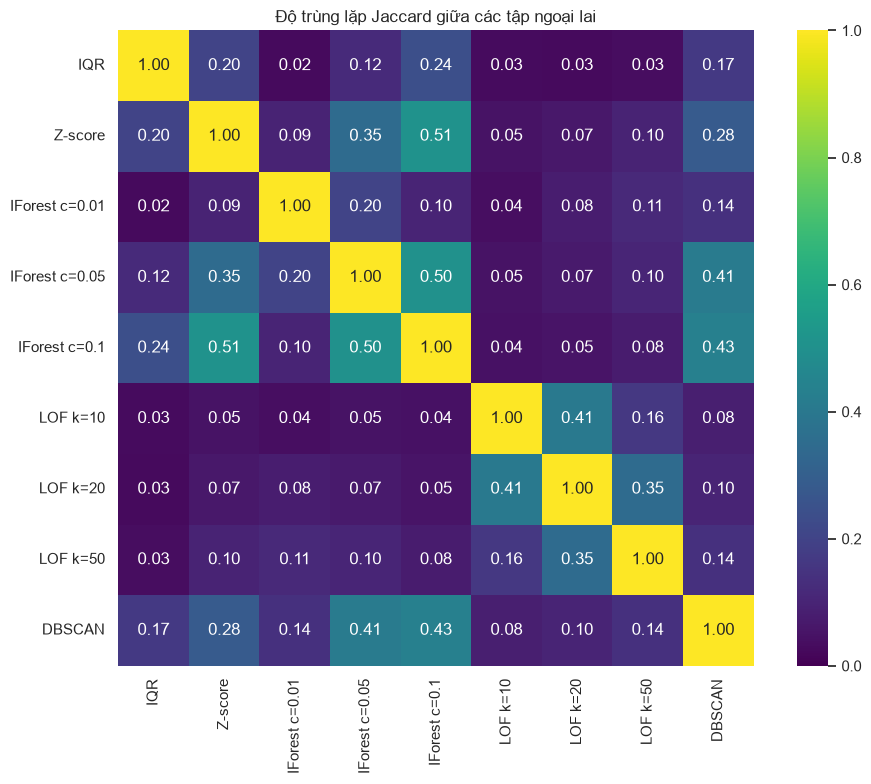

In [ ]:
methods = list(outlier_masks)
jaccard = pd.DataFrame(np.eye(len(methods)), index=methods, columns=methods)
for i, a in enumerate(methods):
    for b in methods[i + 1:]:
        inter = np.sum(outlier_masks[a] & outlier_masks[b])
        union = np.sum(outlier_masks[a] | outlier_masks[b])
        jaccard.loc[a, b] = jaccard.loc[b, a] = inter / union if union else np.nan

plt.figure(figsize=(10, 8))
sns.heatmap(jaccard, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, square=True)
plt.title("Độ trùng lặp Jaccard giữa các tập ngoại lai")
plt.tight_layout()
plt.show()

### Nhận xét độ trùng lặp

Các phương pháp **bất đồng rất lớn**: không cặp nào có Jaccard vượt 0,51.

- **Nhóm "toàn cục"** gồm Z-score, IForest và DBSCAN trùng nhau ở mức trung bình (0,28–0,51). Cả ba đều nhắm vào những điểm nằm xa khối dữ liệu chính, chủ yếu là các dòng có `capital.*` khác 0.
- **LOF gần như tách biệt** với mọi phương pháp còn lại (Jaccard ≤ 0,11), đúng với bản chất cục bộ đã phân tích ở trên.
- **LOF cũng không ổn định theo tham số:** LOF k=10 và k=50 chỉ trùng 0,16. Trên dữ liệu có nhiều giá trị rời rạc và trùng nhau như Adult, khái niệm "mật độ cục bộ" thay đổi mạnh theo kích thước vùng lân cận.
- **IQR** trùng thấp với mọi phương pháp, vì tập ngoại lai của nó quá lớn (41,5%) nên mẫu số $\lvert A \cup B \rvert$ lớn.

Không có "tập ngoại lai đúng" nào được mọi phương pháp đồng thuận. Định nghĩa ngoại lai phụ thuộc hoàn toàn vào phương pháp, nên việc có loại bỏ hay không cần được quyết định bằng tác động thực tế chứ không bằng một phương pháp duy nhất.

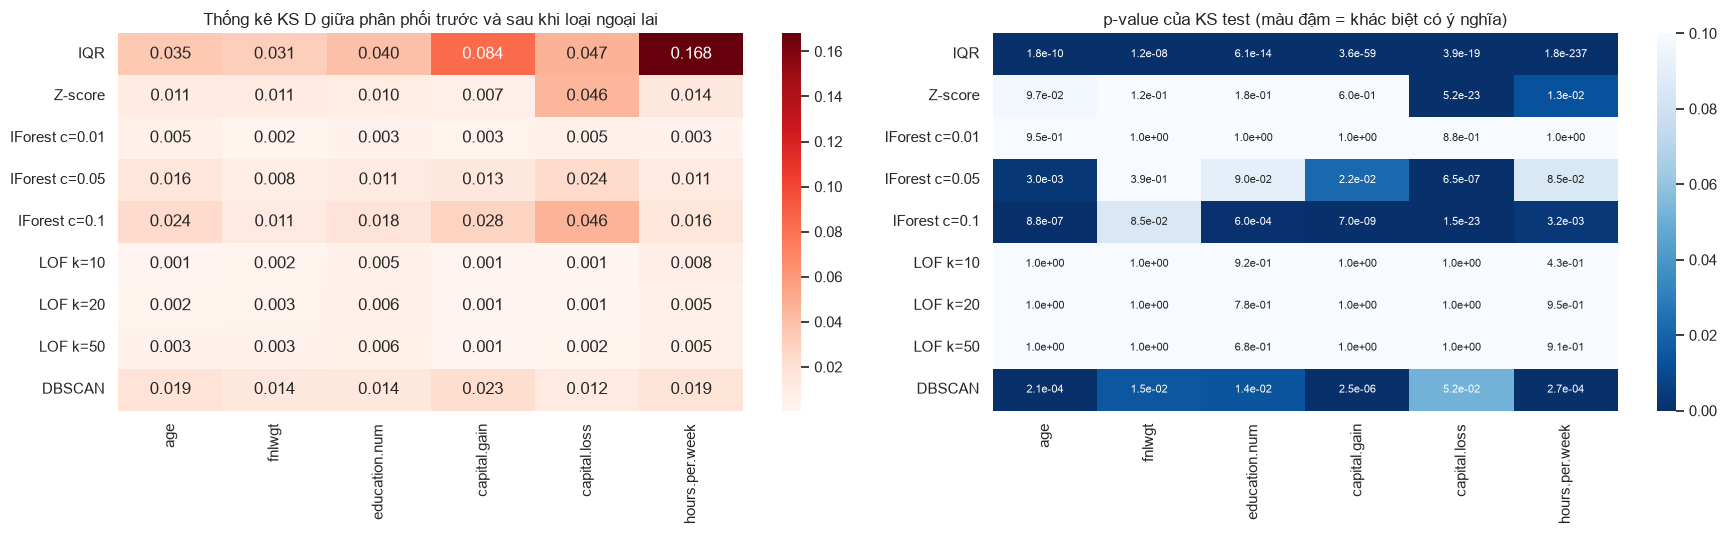

,IQR,Z-score,IForest c=0.01,IForest c=0.05,IForest c=0.1,LOF k=10,LOF k=20,LOF k=50,DBSCAN
số cột thay đổi có ý nghĩa (p<0.05),6,2,0,3,5,0,0,0,5


In [ ]:
ks_D, ks_p = {}, {}
for m, mask in outlier_masks.items():
    ks_D[m], ks_p[m] = {}, {}
    for col in NUM_COLS:
        res = stats.ks_2samp(num_train[col], num_train.loc[~mask, col])
        ks_D[m][col], ks_p[m][col] = res.statistic, res.pvalue
ks_D, ks_p = pd.DataFrame(ks_D).T, pd.DataFrame(ks_p).T
ks_summary = ks_D.copy()
ks_summary["số cột thay đổi có ý nghĩa (p<0.05)"] = (ks_p < ALPHA).sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
sns.heatmap(ks_D, annot=True, fmt=".3f", cmap="Reds", ax=axes[0])
axes[0].set_title("Thống kê KS D giữa phân phối trước và sau khi loại ngoại lai")
sns.heatmap(ks_p, annot=True, fmt=".1e", cmap="Blues_r", ax=axes[1], vmin=0, vmax=0.1, annot_kws={"fontsize": 8})
axes[1].set_title("p-value của KS test (màu đậm = khác biệt có ý nghĩa)")
fig.tight_layout()
plt.show()
ks_summary[["số cột thay đổi có ý nghĩa (p<0.05)"]].T

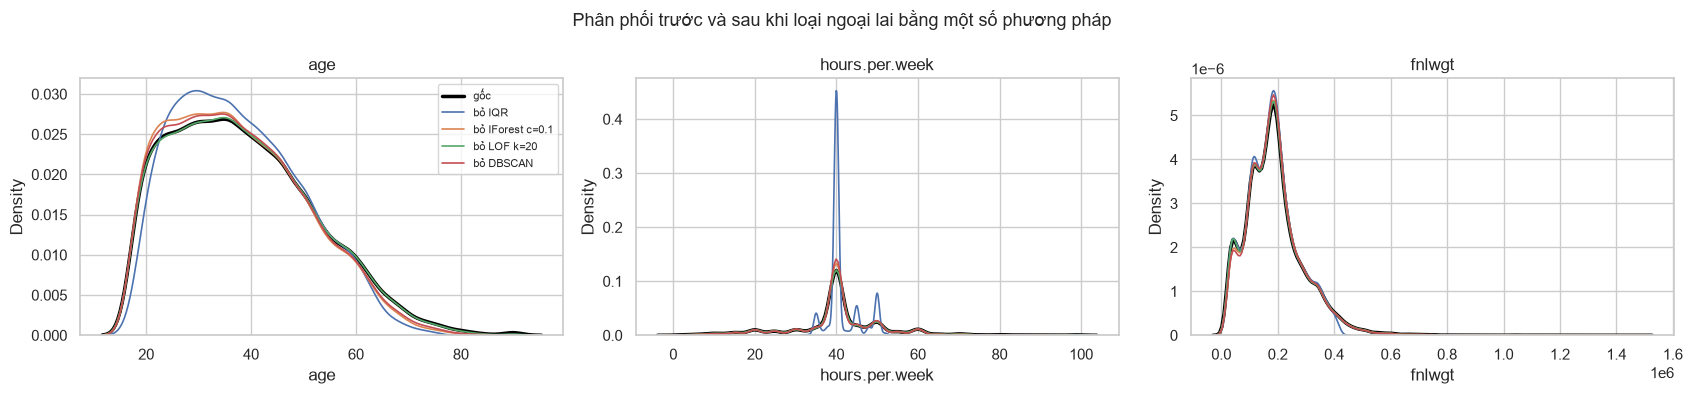

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["age", "hours.per.week", "fnlwgt"]):
    sns.kdeplot(num_train[col], ax=ax, label="gốc", lw=2.5, color="black")
    for m in ["IQR", "IForest c=0.1", "LOF k=20", "DBSCAN"]:
        sns.kdeplot(num_train.loc[~outlier_masks[m], col], ax=ax, label=f"bỏ {m}", lw=1.2)
    ax.set_title(col)
axes[0].legend(fontsize=8)
fig.suptitle("Phân phối trước và sau khi loại ngoại lai bằng một số phương pháp", fontsize=13)
fig.tight_layout()
plt.show()

### Nhận xét KS test

- **IQR thay đổi có ý nghĩa cả 6/6 phân phối.** IForest c=0,1 và DBSCAN thay đổi 5/6, Z-score 2/6, IForest c=0,05 thay đổi 3/6. Loại theo IQR xóa sạch mọi giá trị `capital.*` khác 0 và mọi `hours.per.week` khác 40–45, tức **biến dữ liệu thành một quần thể khác hẳn**.
- **LOF (cả 3 giá trị k) và IForest c=0,01 không làm thay đổi có ý nghĩa phân phối nào.** Các điểm chúng loại rải rác khắp không gian, không tập trung ở đuôi của một biến cụ thể.
- Đồ thị KDE xác nhận: sau khi loại theo IQR, phân phối `hours.per.week` chỉ còn một gai nhọn tại 40.

KS test ở đây so sánh một tập với **tập con** của chính nó, nên hai mẫu không độc lập như giả định của kiểm định. p-value chỉ nên đọc như một thước đo tương đối về mức độ thay đổi. Thống kê $D$ (khoảng cách lớn nhất giữa hai hàm phân phối) mới là đại lượng chính.

### Loại ngoại lai có giúp mô hình tốt hơn không?

KS test cho biết phân phối thay đổi bao nhiêu, nhưng chưa cho biết thay đổi đó có lợi hay có hại. Ta huấn luyện cùng một mô hình trên tập train **đã loại** ngoại lai theo từng phương pháp, rồi đánh giá trên **toàn bộ tập test** (không loại gì, vì khi triển khai ta không được chọn dữ liệu đầu vào). Dùng hai mô hình: Logistic Regression (tuyến tính, nhạy với ngoại lai) và Histogram Gradient Boosting (dạng cây, ít nhạy hơn).

In [ ]:
def log_numeric(X_):
    X_ = pd.DataFrame(X_, columns=NUM_COLS).astype(float)
    return log_space(X_).to_numpy()


def baseline_preprocessor():
    return ColumnTransformer([
        ("num", make_pipeline(FunctionTransformer(log_numeric, feature_names_out="one-to-one"), StandardScaler()), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ("flag", "passthrough", FLAG_COLS),
    ])


def evaluate_on_test(model, X_tr, y_tr, X_te=X_test_imp, y_te=y_test) -> dict:
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {"F1-macro": f1_score(y_te, pred, average="macro"), "AUC": roc_auc_score(y_te, proba)}


outlier_model_rows = []
for m, mask in {"Không loại": np.zeros(len(X_train_imp), bool), **outlier_masks}.items():
    keep = ~mask
    for model_name, clf in [("LogReg", LogisticRegression(max_iter=3000)),
                            ("HGB", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]:
        res = evaluate_on_test(make_pipeline(baseline_preprocessor(), clf), X_train_imp[keep], y_train[keep])
        outlier_model_rows.append({"phương pháp": m, "mô hình": model_name, "số dòng train": int(keep.sum()), **res})
outlier_model_results = pd.DataFrame(outlier_model_rows).pivot_table(
    index="phương pháp", columns="mô hình", values=["F1-macro", "AUC"]).round(4)
outlier_model_results = outlier_model_results.reindex(["Không loại"] + methods)
outlier_model_results

AUC        F1-macro       
mô hình           HGB LogReg      HGB LogReg
phương pháp                                 
Không loại     0.9205 0.8965   0.8035 0.7757
IQR            0.8861 0.8832   0.7492 0.7542
Z-score        0.9121 0.8836   0.7896 0.7547
IForest c=0.01 0.9203 0.8964   0.8018 0.7760
IForest c=0.05 0.9196 0.8965   0.8037 0.7769
IForest c=0.1  0.9120 0.8960   0.7866 0.7743
LOF k=10       0.9212 0.8963   0.8069 0.7766
LOF k=20       0.9211 0.8965   0.8063 0.7762
LOF k=50       0.9201 0.8965   0.8057 0.7758
DBSCAN         0.9201 0.8965   0.8070 0.7778

### Nhận xét và quyết định xử lý ngoại lai

| | HGB F1 | HGB AUC | LogReg F1 |
|---|---|---|---|
| Không loại | 0,8035 | 0,9205 | 0,7757 |
| IQR | **0,7492** (−0,054) | 0,8861 | 0,7542 |
| Z-score | 0,7896 | 0,9121 | 0,7547 |
| IForest c=0,1 | 0,7866 | 0,9120 | 0,7743 |
| LOF, DBSCAN, IForest c ≤ 0,05 | 0,802–0,807 | 0,920–0,921 | 0,776–0,778 |

- **Loại theo IQR, Z-score và IForest c=0,1 làm mô hình kém đi rõ rệt.** Các phương pháp này xóa đúng những người có thu nhập từ vốn, tức nhóm mang nhiều thông tin nhất về lớp >50K. Mô hình huấn luyện thiếu nhóm này sẽ đoán sai khi gặp họ trong tập test.
- Các phương pháp còn lại thay đổi F1 trong khoảng ±0,004, **nhỏ hơn độ lệch chuẩn CV (khoảng 0,007)**, nên không có cải thiện đáng tin cậy.

**Quyết định: không loại bỏ dòng nào.** Các "ngoại lai" của Adult là **giá trị thật và có thông tin** (thu nhập từ vốn, giá trị trần 99999), không phải lỗi đo. Ảnh hưởng của các giá trị cực lớn được xử lý ở bước **scale** (mục 3) thay vì xóa dòng.

## 3. Chuẩn hóa dữ liệu

### Lý thuyết

| Phương pháp | Công thức | Miền giá trị sau biến đổi | Đặc điểm |
|---|---|---|---|
| **Min-Max** | $x' = \dfrac{x - x_{\min}}{x_{\max} - x_{\min}}$ | $[0, 1]$ | Giữ nguyên hình dạng phân phối; một ngoại lai cực lớn sẽ nén mọi giá trị khác về gần 0 |
| **Z-score** | $x' = \dfrac{x - \bar{x}}{s}$ | không bị chặn | Trung bình 0, độ lệch chuẩn 1; $\bar{x}$ và $s$ nhạy với ngoại lai |
| **Robust** | $x' = \dfrac{x - \operatorname{median}(x)}{Q_3 - Q_1}$ | không bị chặn | Bền vững với ngoại lai; suy biến khi IQR = 0 |
| **Quantile** | $x' = \Phi^{-1}\!\left(\hat{F}(x)\right)$ | xấp xỉ $\mathcal{N}(0, 1)$ | Phép biến đổi phi tuyến, đơn điệu; ép mọi phân phối về dạng chuẩn, làm mất thông tin khoảng cách giữa các giá trị |

Ở đây $\hat{F}$ là hàm phân phối thực nghiệm và $\Phi^{-1}$ là hàm phân vị của phân phối chuẩn tắc.

**Levene test** kiểm định tính đồng nhất phương sai (homoscedasticity) giữa $k$ nhóm:

$$W = \frac{(N-k)}{(k-1)} \cdot \frac{\sum_{i=1}^{k} N_i (\bar{Z}_{i\cdot} - \bar{Z}_{\cdot\cdot})^2}{\sum_{i=1}^{k}\sum_{j=1}^{N_i} (Z_{ij} - \bar{Z}_{i\cdot})^2}, \qquad Z_{ij} = \lvert x_{ij} - \tilde{x}_{i} \rvert,$$

với $\tilde{x}_i$ là median của nhóm $i$ (biến thể Brown-Forsythe, bền vững với phân phối lệch). Ở đây **mỗi thuộc tính là một nhóm**: ta kiểm tra xem sau khi scale, các thuộc tính có độ phân tán tương đương nhau không. Đây là điều kiện để mỗi thuộc tính đóng góp ngang nhau vào khoảng cách trong kNN, SVM hay K-Means.

Ngoài 4 phương pháp áp dụng đồng loạt cho mọi cột, ta kiểm chứng thêm **kế hoạch theo từng cột** đề xuất từ EDA:

- `age`, `education.num`: Min-Max.
- `fnlwgt`: $\log$ rồi Robust.
- `capital.*`: $\log(1+x)$ rồi Min-Max, kèm biến nhị phân $\mathbb{1}[x > 0]$.
- `hours.per.week`: thử cả Robust và Quantile.

Cuối cùng là một phương án hiệu chỉnh: **Robust** cho `age`, `education.num`, `hours.per.week` và $\log$(`fnlwgt`), còn `capital.*` được lấy $\log(1+x)$ rồi Z-score. Phương án này giữ ưu điểm của Robust nhưng tránh được việc Robust suy biến khi IQR = 0.

**Quy tắc chọn:** chọn phương án có F1 kNN cao nhất, với điều kiện sau khi scale **không còn cột nào có $\lvert x' 
vert > 50$**. Một cột còn giá trị cực lớn nghĩa là phép scale không đưa được nó về cùng thang đo với các cột khác.

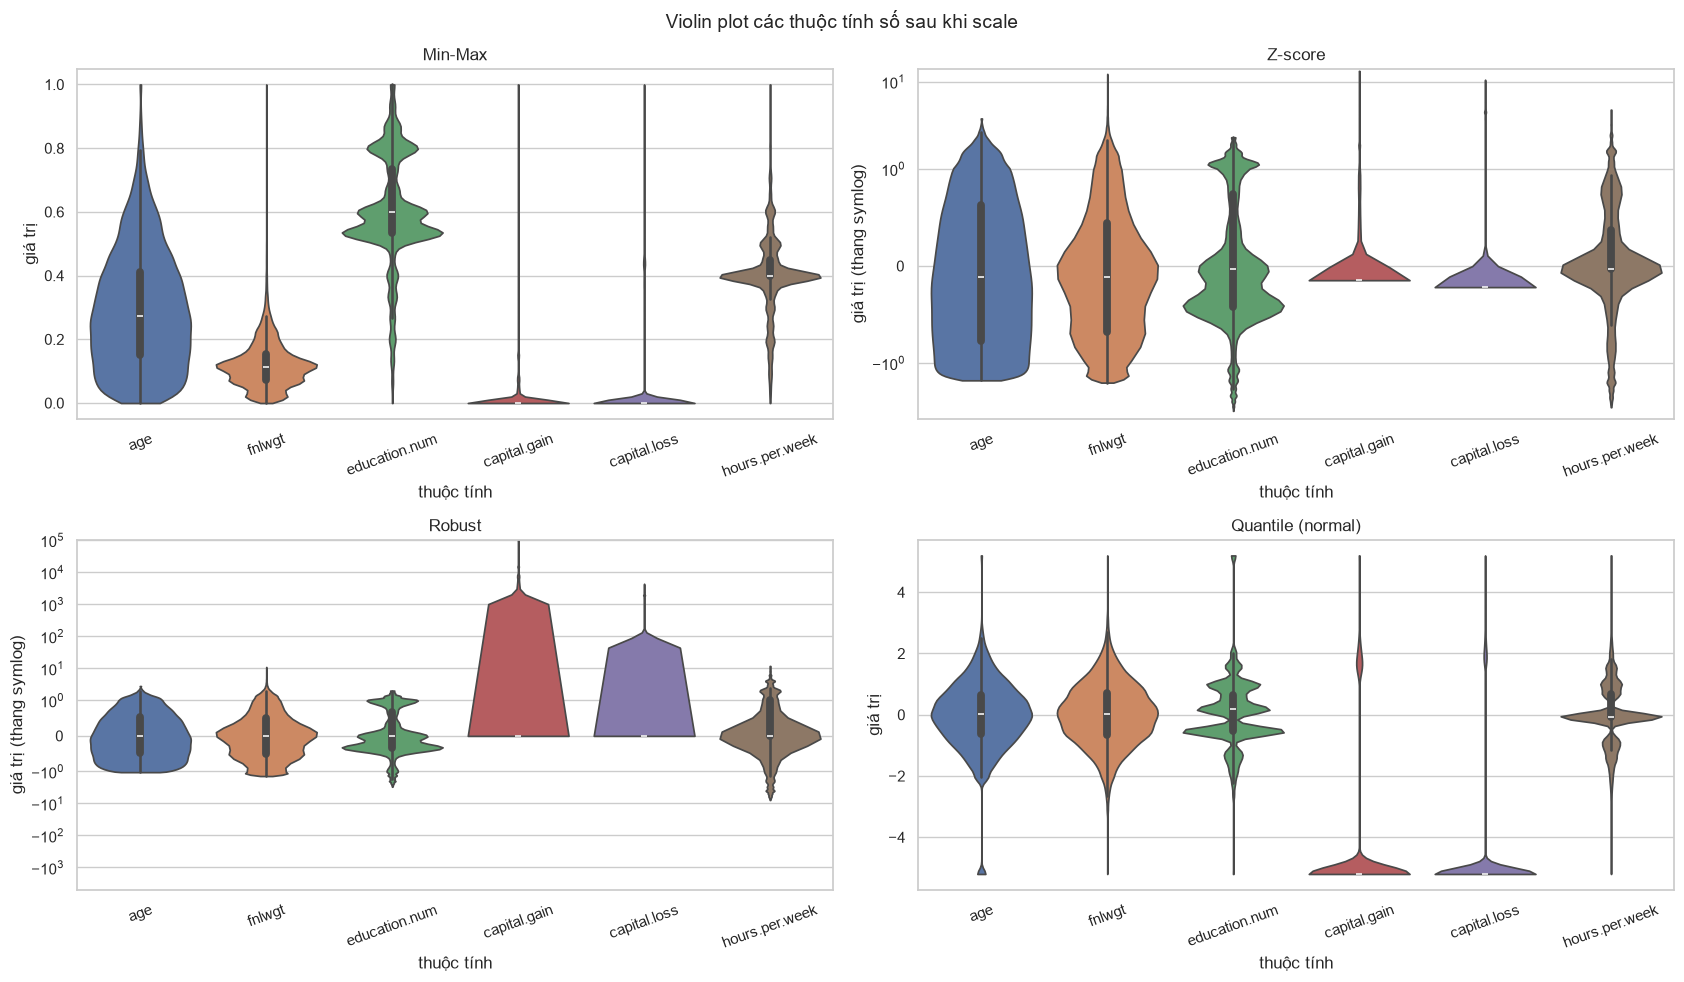

In [ ]:
SCALERS = {
    "Min-Max": MinMaxScaler,
    "Z-score": StandardScaler,
    "Robust": RobustScaler,
    "Quantile (normal)": lambda: QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=RANDOM_STATE),
}
scaled = {name: pd.DataFrame(make().fit_transform(num_train), columns=NUM_COLS) for name, make in SCALERS.items()}

fig, axes = plt.subplots(2, 2, figsize=(17, 10))
for ax, (name, data) in zip(axes.ravel(), scaled.items()):
    long = data.melt(var_name="thuộc tính", value_name="giá trị")
    sns.violinplot(data=long, x="thuộc tính", y="giá trị", hue="thuộc tính", cut=0, density_norm="width", ax=ax, legend=False)
    if name in ("Z-score", "Robust"):
        ax.set_yscale("symlog", linthresh=1)
        ax.set_ylabel("giá trị (thang symlog)")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Violin plot các thuộc tính số sau khi scale", fontsize=14)
fig.tight_layout()
plt.show()

In [ ]:
levene_rows, spread_rows = [], []
for name, data in scaled.items():
    W, p = stats.levene(*[data[c] for c in NUM_COLS], center="median")
    levene_rows.append({"phương pháp": name, "Levene W": W, "p-value": p})
    for c in NUM_COLS:
        spread_rows.append({"phương pháp": name, "thuộc tính": c, "std": data[c].std(),
                            "IQR": data[c].quantile(0.75) - data[c].quantile(0.25),
                            "min": data[c].min(), "max": data[c].max()})
levene_results = pd.DataFrame(levene_rows).set_index("phương pháp")
spread_table = pd.DataFrame(spread_rows).pivot_table(index="thuộc tính", columns="phương pháp", values=["std", "max"])
display(levene_results)
spread_table.round(3)

,Levene W,p-value
phương pháp,,
Min-Max,"9,458.6647",0.0000
Z-score,"3,235.4657",0.0000
Robust,543.6406,0.0000
Quantile (normal),606.5493,0.0000


max                                           std  \
phương pháp    Min-Max Quantile (normal)      Robust Z-score Min-Max   
thuộc tính                                                             
age             1.0000            5.1990      2.7890  3.7810  0.1870   
capital.gain    1.0000            5.1990 99,999.0000 13.2460  0.0750   
capital.loss    1.0000            5.1990  4,356.0000 10.4950  0.0930   
education.num   1.0000            5.1990      2.0000  2.3010  0.1710   
fnlwgt          1.0000            5.1990     10.9580 12.2330  0.0720   
hours.per.week  1.0000            5.1990     11.8000  4.7660  0.1250   

                                                     
phương pháp    Quantile (normal)     Robust Z-score  
thuộc tính                                           
age                       1.1180     0.7170  1.0000  
capital.gain              2.0090 7,466.7780  1.0000  
capital.loss              1.5460   406.6260  1.0000  
education.num             1.1030     0.8570  1.0000  
fnlwgt                    0.9880     0.8880  1.0000  
hours.per.week            0.9890     2.4570  1.0000

**Kiểm chứng bằng mô hình nhạy với khoảng cách.** kNN là mô hình chịu ảnh hưởng trực tiếp của cách scale, vì thuộc tính có độ phân tán lớn sẽ áp đảo khoảng cách. Ta so sánh F1-macro trung bình qua 5-fold CV của kNN ($k = 25$) và Logistic Regression khi phần số được scale bằng từng phương pháp. Phần phân loại luôn dùng One-Hot.

In [ ]:
def has_positive(X_):
    return (np.asarray(X_, dtype=float) > 0).astype(float)


def has_positive_names(_, cols):
    return np.array([f"{c}>0" for c in cols])


def eda_plan(hours_scaler):
    return ColumnTransformer([
        ("minmax", MinMaxScaler(), ["age", "education.num"]),
        ("fnlwgt", make_pipeline(FunctionTransformer(np.log, feature_names_out="one-to-one"), RobustScaler()), ["fnlwgt"]),
        ("capital", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), MinMaxScaler()),
         ["capital.gain", "capital.loss"]),
        ("capflag", FunctionTransformer(has_positive, feature_names_out=has_positive_names), ["capital.gain", "capital.loss"]),
        ("hours", hours_scaler, ["hours.per.week"]),
    ], verbose_feature_names_out=False)


def robust_log_plan():
    return ColumnTransformer([
        ("robust", RobustScaler(), ["age", "education.num", "hours.per.week"]),
        ("fnlwgt", make_pipeline(FunctionTransformer(np.log, feature_names_out="one-to-one"), RobustScaler()), ["fnlwgt"]),
        ("capital", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()),
         ["capital.gain", "capital.loss"]),
    ], verbose_feature_names_out=False)


NUM_TRANSFORMERS = {
    **{name: make for name, make in SCALERS.items()},
    "Robust + log1p→Z-score (capital)": robust_log_plan,
    "Kế hoạch EDA (hours: Robust)": lambda: eda_plan(RobustScaler()),
    "Kế hoạch EDA (hours: Quantile)": lambda: eda_plan(
        QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=RANDOM_STATE)),
}


def make_preprocessor(num_transformer, cat_parts=None):
    if cat_parts is None:
        cat_parts = [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS)]
    return ColumnTransformer([("num", num_transformer, NUM_COLS), *cat_parts, ("flag", "passthrough", FLAG_COLS)],
                             verbose_feature_names_out=False)


scaling_cv_rows = []
for name, make in NUM_TRANSFORMERS.items():
    for model_name, clf in [("kNN (k=25)", KNeighborsClassifier(n_neighbors=25)), ("LogReg", LogisticRegression(max_iter=3000))]:
        scores = cross_val_score(make_pipeline(make_preprocessor(make()), clf), X_train_imp, y_train,
                                 cv=CV, scoring="f1_macro", n_jobs=-1)
        scaling_cv_rows.append({"cách scale": name, "mô hình": model_name, "F1 TB": scores.mean(), "F1 std": scores.std()})
scaling_cv = pd.DataFrame(scaling_cv_rows).pivot_table(index="cách scale", columns="mô hình", values=["F1 TB", "F1 std"])
scaling_cv = scaling_cv.sort_values(("F1 TB", "kNN (k=25)"), ascending=False)

# Kiểm tra suy biến: có cột nào vẫn còn giá trị rất lớn sau khi scale không?
MAX_ABS_LIMIT = 50
scaling_cv[("max |giá trị| sau scale", "")] = [
    float(np.abs(NUM_TRANSFORMERS[name]().fit_transform(num_train)).max()) for name in scaling_cv.index]
eligible_scalers = scaling_cv[scaling_cv[("max |giá trị| sau scale", "")] <= MAX_ABS_LIMIT]
FINAL_NUM_TRANSFORMER = eligible_scalers.index[0]
print("Phương án có F1 kNN cao nhất (chưa xét suy biến):", scaling_cv.index[0])
print(f"Phương án được chọn (F1 kNN cao nhất trong các phương án có max |giá trị| ≤ {MAX_ABS_LIMIT}):", FINAL_NUM_TRANSFORMER)
scaling_cv.round(4)

Phương án có F1 kNN cao nhất (chưa xét suy biến): Robust
Phương án được chọn (F1 kNN cao nhất trong các phương án có max |giá trị| ≤ 50): Quantile (normal)


F1 TB            F1 std             \
mô hình                          LogReg kNN (k=25) LogReg kNN (k=25)   
cách scale                                                             
Robust                           0.7828     0.8060 0.0070     0.0066   
Quantile (normal)                0.7735     0.7843 0.0074     0.0067   
Z-score                          0.7836     0.7799 0.0076     0.0081   
Robust + log1p→Z-score (capital) 0.7738     0.7774 0.0085     0.0092   
Min-Max                          0.7812     0.7616 0.0073     0.0074   
Kế hoạch EDA (hours: Quantile)   0.7804     0.7580 0.0079     0.0065   
Kế hoạch EDA (hours: Robust)     0.7795     0.7540 0.0081     0.0082   

                                 max |giá trị| sau scale  
mô hình                                                   
cách scale                                                
Robust                                       99,999.0000  
Quantile (normal)                                 5.1993  
Z-score                                          13.2460  
Robust + log1p→Z-score (capital)                 11.8000  
Min-Max                                           1.0000  
Kế hoạch EDA (hours: Quantile)                    5.1993  
Kế hoạch EDA (hours: Robust)                     11.8000

### Nhận xét chuẩn hóa

**Levene test:** cả 4 phương pháp đều bác bỏ $H_0$ (p ≈ 0). Không phép scale tuyến tính nào làm độ phân tán của 6 thuộc tính đồng nhất thực sự, vì hình dạng phân phối của chúng quá khác nhau. Thống kê $W$ vẫn cho biết mức độ:

- **Min-Max** kém nhất ($W$ = 9.459). `capital.gain` bị nén về gần 0 (std 0,075) do một giá trị 99999 chiếm hết khoảng $[0, 1]$.
- **Z-score** ($W$ = 3.235): độ lệch chuẩn đều bằng 1, nhưng `capital.gain` vẫn trải tới 13,2 và `fnlwgt` tới 12,2.
- **Robust** ($W$ = 544) và **Quantile** ($W$ = 607) đồng nhất hơn. Riêng với Robust, đây là "đồng nhất giả": `capital.*` có IQR bằng 0 nên được **giữ nguyên giá trị gốc** (tới 99999, std 7.467). Robust suy biến đúng như EDA đã cảnh báo.
- **Quantile** ép mọi cột về dạng chuẩn, nhưng biến `capital.*` thành phân phối **hai cụm nhân tạo** (khối 0 tại −5,2 và phần khác 0 quanh +2). Thông tin về độ lớn của khoản lãi cũng bị mất: lãi 3.000 hay 99.999 đều nằm trong cùng một vùng hẹp.

**Kiểm chứng bằng kNN:**

- **Robust cho F1 kNN cao nhất (0,806), nhưng vì một lý do sai.** `capital.gain` chưa được scale nên **lấn át hoàn toàn khoảng cách**: mọi người có lãi vốn đều "xa" mọi người không có. kNN trở thành gần như một luật dựa trên `capital.gain`, mà biến này dự đoán rất tốt lớp >50K. Đây là một phép đánh trọng số đặc trưng vô tình, không phải một cách scale tốt: trong lần chạy thử, PCA trên ma trận này cho **1 thành phần giải thích 99% phương sai**. Quy tắc "max |giá trị| ≤ 50" loại phương án này.
- **Quantile được chọn** (kNN 0,784). Nó đưa mọi cột về cùng thang đo và cân bằng tốt với hơn 80 cột One-Hot dạng 0/1.
- **Đánh đổi:** với Logistic Regression, Quantile (0,774) lại *kém* Z-score (0,784). Mô hình tuyến tính cần độ lớn của `capital.gain` (lãi càng lớn thì xác suất >50K càng cao), mà Quantile đã nén mất thông tin này. Không có cách scale tốt nhất cho mọi mô hình.
- **Kế hoạch theo từng cột từ EDA cho kNN kém nhất (0,754–0,758).** Min-Max đưa `age` và `education.num` về $[0, 1]$, độ phân tán nhỏ hơn hẳn các cột One-Hot, nên các biến số mất trọng lượng trong khoảng cách. Robust và Quantile cho `hours.per.week` chênh nhau không đáng kể (0,754 so với 0,758). **Bài học:** một kế hoạch hợp lý xét riêng từng cột chưa chắc tốt, vì với mô hình khoảng cách, điều quan trọng là **cân bằng độ phân tán giữa các cột** (biến số so với biến One-Hot) chứ không chỉ hình dạng của từng cột.

## 4. Mã hóa biến phân loại nâng cao

### Lý thuyết

Xét biến phân loại $c$ có $K$ mức $\{v_1, \dots, v_K\}$:

| Phương pháp | Biểu diễn | Số cột | Ghi chú |
|---|---|---|---|
| **One-Hot** | $\mathbb{1}[c = v_k]$ với $k = 1..K$ | $K$, hoặc $K-1$ nếu bỏ một mức | Giữ đủ $K$ cột gây **bẫy biến giả** (dummy variable trap): $\sum_k \mathbb{1}[c = v_k] = 1$ là tổ hợp tuyến tính hoàn hảo với hệ số chặn |
| **Ordinal** | số nguyên $1..K$ | 1 | Áp đặt thứ tự và khoảng cách giả tạo nếu biến không có thứ tự |
| **Frequency** | $\hat{P}(c = v_k) = n_k / n$ | 1 | Không dùng nhãn nên không rò rỉ; hai mức có cùng tần suất sẽ bị gộp làm một |
| **Target (mean)** | $\hat{\mu}_k$ (xem công thức dưới) | 1 | Mạnh nhưng dễ **rò rỉ nhãn**, cần cross-fitting |
| **Binary** | biểu diễn nhị phân của mã thứ tự | $\lceil \log_2(K+1) \rceil$ | Gọn cho biến nhiều mức: 41 quốc gia chỉ cần 6 cột thay vì 41 |

**Target encoding có làm trơn (smoothing)**:

$$\hat{\mu}_k = \lambda_k\, \bar{y}_k + (1 - \lambda_k)\, \bar{y}, \qquad \lambda_k = \frac{n_k}{n_k + m}.$$

Mức hiếm ($n_k$ nhỏ) bị kéo về trung bình chung $\bar{y}$. Nếu tính $\bar{y}_k$ trên chính những dòng sẽ dùng để huấn luyện, nhãn $y_i$ của mỗi dòng đã "nằm sẵn" trong đặc trưng của nó, gây **rò rỉ nhãn**. `TargetEncoder` của scikit-learn khắc phục bằng **cross-fitting 5-fold**: đặc trưng của các dòng ở fold $f$ được tính từ nhãn của 4 fold còn lại.

**Đánh giá đa cộng tuyến do mã hóa sinh ra:**

- **VIF** của từng cột, $\text{VIF}_j = 1/(1 - R_j^2)$. Giá trị $\infty$ nghĩa là có một cột là tổ hợp tuyến tính hoàn hảo của các cột khác.
- **Explained variance ratio của PCA** trên ma trận đặc trưng đã chuẩn hóa: nếu cần ít thành phần để giải thích 95% phương sai so với số cột, ma trận có nhiều thông tin dư thừa. Số trị riêng bằng 0 đúng bằng số **phụ thuộc tuyến tính chính xác**.

Phần số dùng cách scale đã chọn ở mục 3 cho mọi phương án mã hóa, nên mọi khác biệt chỉ đến từ cách mã hóa.

In [ ]:
class FrequencyEncoder(BaseEstimator, TransformerMixin):
    # Thay mỗi mức bằng tần suất của nó trên tập huấn luyện; mức chưa gặp được gán 0.

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = list(X.columns)
        self.freq_ = {c: X[c].value_counts(normalize=True) for c in self.columns_}
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_)
        return np.column_stack([X[c].map(self.freq_[c]).astype(float).fillna(0.0).to_numpy() for c in self.columns_])

    def get_feature_names_out(self, input_features=None):
        return np.array([f"{c}_freq" for c in self.columns_])


class BinaryEncoder(BaseEstimator, TransformerMixin):
    # Mã thứ tự 1..K (0 dành cho mức chưa gặp) rồi viết ra dạng nhị phân với ceil(log2(K+1)) bit.

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = list(X.columns)
        self.codes_ = {c: {v: i + 1 for i, v in enumerate(sorted(X[c].dropna().unique()))} for c in self.columns_}
        self.n_bits_ = {c: int(np.ceil(np.log2(len(self.codes_[c]) + 1))) for c in self.columns_}
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_)
        parts = []
        for c in self.columns_:
            codes = X[c].map(self.codes_[c]).fillna(0).astype(int).to_numpy()
            shifts = np.arange(self.n_bits_[c])[::-1]
            parts.append((codes[:, None] >> shifts) & 1)
        return np.hstack(parts).astype(float)

    def get_feature_names_out(self, input_features=None):
        return np.array([f"{c}_bit{b}" for c in self.columns_ for b in range(self.n_bits_[c])])


HIGH_CARD = [c for c in CAT_COLS if X_train_imp[c].nunique() > 20]
LOW_CARD = [c for c in CAT_COLS if c not in HIGH_CARD]
print("Biến có trên 20 mức (dùng Binary Encoding):", {c: X_train_imp[c].nunique() for c in HIGH_CARD})
print("Minh họa Binary Encoding cho 4 quốc gia:")
_be = BinaryEncoder().fit(X_train_imp[HIGH_CARD])
_demo = pd.DataFrame({"native.country": ["United-States", "Mexico", "Vietnam", "Holand-Netherlands"]})
pd.DataFrame(_be.transform(_demo).astype(int), columns=_be.get_feature_names_out(), index=_demo["native.country"])

Biến có trên 20 mức (dùng Binary Encoding): {'native.country': 40}
Minh họa Binary Encoding cho 4 quốc gia:


,native.country_bit0,native.country_bit1,native.country_bit2,native.country_bit3,native.country_bit4,native.country_bit5
native.country,,,,,,
United-States,1,0,0,1,1,0
Mexico,0,1,1,0,0,1
Vietnam,1,0,0,1,1,1
Holand-Netherlands,0,0,0,0,0,0


In [ ]:
def ohe(drop=None):
    return OneHotEncoder(drop=drop, handle_unknown="ignore", sparse_output=False)


ENCODINGS = {
    "One-Hot (đủ K cột)": lambda: [("cat", ohe(), CAT_COLS)],
    "One-Hot (drop first)": lambda: [("cat", ohe("first"), CAT_COLS)],
    "Ordinal": lambda: [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_COLS)],
    "Frequency": lambda: [("cat", FrequencyEncoder(), CAT_COLS)],
    "Target (CV 5-fold)": lambda: [("cat", TargetEncoder(target_type="binary", cv=5, random_state=RANDOM_STATE), CAT_COLS)],
    "One-Hot + Binary (native.country)": lambda: [("low", ohe("first"), LOW_CARD), ("high", BinaryEncoder(), HIGH_CARD)],
}
final_num = NUM_TRANSFORMERS[FINAL_NUM_TRANSFORMER]


def vif_all(Xm: np.ndarray) -> np.ndarray:
    # VIF_j = 1 / (1 - R_j^2), R_j^2 từ hồi quy OLS cột j theo các cột còn lại (có hệ số chặn)
    Xm = Xm[:, Xm.std(axis=0) > 0]
    Xm = (Xm - Xm.mean(axis=0)) / Xm.std(axis=0)
    out = np.empty(Xm.shape[1])
    for j in range(Xm.shape[1]):
        others = np.column_stack([np.ones(len(Xm)), np.delete(Xm, j, axis=1)])
        coef, *_ = np.linalg.lstsq(others, Xm[:, j], rcond=None)
        resid = Xm[:, j] - others @ coef
        r2 = 1 - resid.var() / Xm[:, j].var()
        out[j] = np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2)
    return out


enc_rows, enc_matrices = [], {}
for name, parts in ENCODINGS.items():
    pre = make_preprocessor(final_num(), parts())
    Xe = pre.fit_transform(X_train_imp, y_train)
    enc_matrices[name] = pd.DataFrame(Xe, columns=pre.get_feature_names_out())
    Xs = StandardScaler().fit_transform(Xe[:, Xe.std(axis=0) > 0])
    pca = PCA().fit(Xs)
    cum = np.cumsum(pca.explained_variance_ratio_)
    vifs = vif_all(Xe)
    row = {"phương án": name, "số cột": Xe.shape[1],
           "PC1 giải thích (%)": pca.explained_variance_ratio_[0] * 100,
           "số PC đạt 95%": int(np.searchsorted(cum, 0.95) + 1),
           "trị riêng ≈ 0": int(np.sum(pca.explained_variance_ < 1e-10)),
           "VIF max": vifs.max(), "VIF trung vị": np.median(vifs),
           "số cột VIF > 10": int(np.sum(vifs > 10))}
    for model_name, clf in [("LogReg", LogisticRegression(max_iter=3000)),
                            ("HGB", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]:
        scores = cross_val_score(make_pipeline(make_preprocessor(final_num(), parts()), clf),
                                 X_train_imp, y_train, cv=CV, scoring="f1_macro", n_jobs=-1)
        row[f"F1 CV {model_name}"] = scores.mean()
    enc_rows.append(row)
encoding_results = pd.DataFrame(enc_rows).set_index("phương án")
encoding_results["số PC 95% / số cột"] = encoding_results["số PC đạt 95%"] / encoding_results["số cột"]
encoding_results

,số cột,PC1 giải thích (%),số PC đạt 95%,trị riêng ≈ 0,VIF max,VIF trung vị,số cột VIF > 10,F1 CV LogReg,F1 CV HGB,số PC 95% / số cột
phương án,,,,,,,,,,
One-Hot (đủ K cột),90,5.0794,73,8,inf,inf,83,0.7735,0.8179,0.8111
One-Hot (drop first),83,4.1080,69,1,inf,2.2859,10,0.7731,0.8157,0.8313
Ordinal,14,15.5723,13,0,1.6920,1.0403,0,0.7071,0.8163,0.9286
Frequency,14,17.4898,13,0,2.2462,1.0954,0,0.7366,0.8174,0.9286
Target (CV 5-fold),14,21.0149,12,0,17.9536,1.1265,2,0.7651,0.8155,0.8571
One-Hot + Binary (native.country),50,9.3326,38,1,inf,1.9941,7,0.7727,0.8156,0.7600


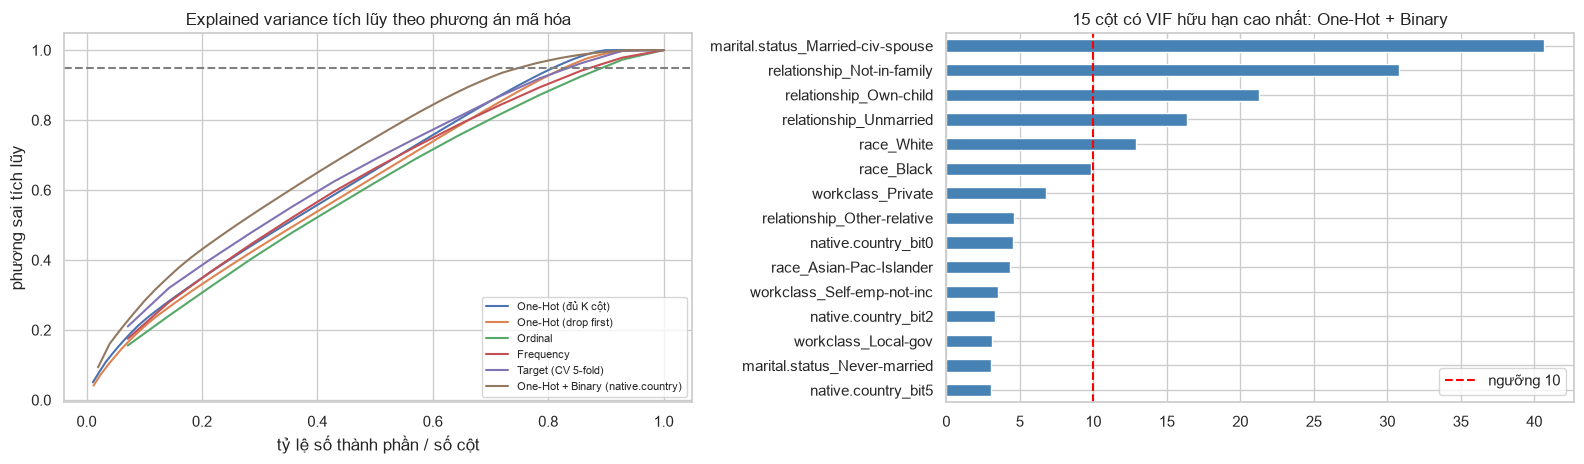

Các cột có VIF = ∞: ['workclass_Never-worked', 'occupation_None']
Hai cột này giống hệt nhau trên mọi dòng: True, số dòng bằng 1: 6


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for name, Xe in enc_matrices.items():
    Xs = StandardScaler().fit_transform(Xe.loc[:, Xe.std() > 0])
    cum = np.cumsum(PCA().fit(Xs).explained_variance_ratio_)
    axes[0].plot(np.arange(1, len(cum) + 1) / len(cum), cum, label=name)
axes[0].axhline(0.95, ls="--", color="gray")
axes[0].set(xlabel="tỷ lệ số thành phần / số cột", ylabel="phương sai tích lũy", title="Explained variance tích lũy theo phương án mã hóa")
axes[0].legend(fontsize=8)

vif_ohe = pd.Series(vif_all(enc_matrices["One-Hot + Binary (native.country)"].to_numpy()),
                    index=enc_matrices["One-Hot + Binary (native.country)"].columns).sort_values(ascending=False)
inf_vif_cols = vif_ohe[np.isinf(vif_ohe)].index.tolist()
vif_plot = vif_ohe.replace(np.inf, np.nan).dropna().head(15)
vif_plot.iloc[::-1].plot.barh(ax=axes[1], color="steelblue")
axes[1].axvline(10, color="red", ls="--", label="ngưỡng 10")
axes[1].set_title("15 cột có VIF hữu hạn cao nhất: One-Hot + Binary")
axes[1].legend()
fig.tight_layout()
plt.show()

print("Các cột có VIF = ∞:", inf_vif_cols)
Xe_ohb = enc_matrices["One-Hot + Binary (native.country)"]
if len(inf_vif_cols) == 2:
    a, b = inf_vif_cols
    print(f"Hai cột này giống hệt nhau trên mọi dòng: {bool((Xe_ohb[a] == Xe_ohb[b]).all())}, số dòng bằng 1: {int(Xe_ohb[a].sum())}")

### Nhận xét mã hóa

**1. Bẫy biến giả được xác nhận bằng số.** One-Hot đủ $K$ cột có **8 trị riêng bằng 0**: 7 phụ thuộc tuyến tính (mỗi biến phân loại có các cột cộng lại bằng 1) cộng thêm 1. Mọi cột đều có VIF = ∞. Bỏ một mức mỗi biến (drop first) còn đúng **1 trị riêng bằng 0**.

**2. Trị riêng bằng 0 còn lại là một phát hiện mới.** `workclass_Never-worked` và `occupation_None` **giống hệt nhau trên mọi dòng** (6 người trong train). Đây là hệ quả của quyết định gán `occupation = "None"` cho người `Never-worked` ở mục 0. Nó minh họa rằng **một bước tiền xử lý có thể sinh ra đa cộng tuyến mới**. Bước chọn đặc trưng ở mục 5 loại cả hai cột này.

**3. Cụm `marital.status` và `relationship` gây VIF cao**, đúng như EDA dự báo từ Cramér's V: `Married-civ-spouse` 40,6, `relationship_Not-in-family` 30,8, `Own-child` 21,2, `Unmarried` 16,3. Ngoài ra còn `race_White` 12,9, vì `White` và `Black` gần như bù trừ nhau.

**4. Mã hóa gọn và hiệu năng:**

| | Số cột | VIF max | LogReg F1 | HGB F1 |
|---|---|---|---|---|
| One-Hot (drop first) | 83 | ∞ (1 cặp trùng) | 0,7731 | 0,8157 |
| One-Hot + Binary | 50 | ∞ (1 cặp trùng) | 0,7727 | 0,8156 |
| Target (CV) | 14 | 17,95 | 0,7651 | 0,8155 |
| Frequency | 14 | 2,25 | 0,7366 | 0,8174 |
| Ordinal | 14 | 1,69 | **0,7071** | 0,8163 |

- **Ordinal và Frequency có VIF rất thấp nhưng làm Logistic Regression kém hẳn** (giảm 0,04–0,07). Mô hình tuyến tính buộc phải coi mã 1, 2, 3... (hoặc tần suất) là đại lượng có thứ tự, trong khi các mức nghề nghiệp không có thứ tự như vậy. VIF thấp không có nghĩa là biểu diễn tốt.
- **HGB gần như không bị ảnh hưởng** (0,816–0,818 cho mọi phương án): cây quyết định có thể tách mã số theo bất kỳ ngưỡng nào, nên tự học lại được nhóm các mức.
- **Target Encoding** gọn nhất mà vẫn giữ được thông tin (LogReg 0,765), nhưng tạo VIF 17,95. Mọi cột đều được biến đổi thành "xác suất >50K theo mức", nên `relationship` và `marital.status` sau mã hóa tương quan rất mạnh với nhau.
- **Explained variance:** các phương án gọn có PC1 giải thích nhiều hơn (Target 21%, Frequency 17,5%, so với 4,1% của One-Hot). Thông tin dồn vào ít chiều hơn. One-Hot + Binary có tỷ lệ số PC đạt 95% trên số cột thấp nhất (0,76), cho thấy 6 bit của `native.country` khá dư thừa với nhau (41 quốc gia nhưng 91% là `United-States`).

**Lựa chọn: One-Hot (drop first) + Binary cho `native.country`.** Phương án này giữ hiệu năng Logistic Regression ngang One-Hot đầy đủ (chênh 0,0004) với **ít hơn 40% số cột** (50 so với 83). Mỗi cột có ý nghĩa riêng, không có rủi ro rò rỉ nhãn, và VIF chỉ vô hạn ở cặp trùng lặp mà bước chọn đặc trưng sẽ loại.

### Minh họa rò rỉ nhãn của Target Encoding

Rò rỉ nhãn thể hiện rõ nhất với biến có **rất nhiều mức**. Ta cố ý coi `fnlwgt` (khoảng 21.000 giá trị khác nhau) là biến phân loại rồi so sánh hai cách:

- **Target encoding "ngây thơ":** tính $\bar{y}_k$ trên toàn bộ tập train rồi dùng luôn cho chính tập đó.
- **Target encoding cross-fitting 5-fold** (`TargetEncoder`).

Sau đó huấn luyện Logistic Regression **chỉ trên đặc trưng này** và so sánh F1 trên train với F1 trên test.

In [ ]:
leak_tr = X_train_imp[["fnlwgt"]].astype(str)
leak_te = X_test_imp[["fnlwgt"]].astype(str)

naive_map = y_train.groupby(leak_tr["fnlwgt"]).mean()
naive_tr = leak_tr["fnlwgt"].map(naive_map).to_numpy()[:, None]
naive_te = leak_te["fnlwgt"].map(naive_map).fillna(y_train.mean()).to_numpy()[:, None]

te = TargetEncoder(target_type="binary", cv=5, random_state=RANDOM_STATE)
cv_tr = te.fit_transform(leak_tr, y_train)
cv_te = te.transform(leak_te)

leak_rows = []
for name, (a, b) in {"Ngây thơ (không CV)": (naive_tr, naive_te), "Cross-fitting 5-fold": (cv_tr, cv_te)}.items():
    lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(a, y_train)
    leak_rows.append({"cách mã hóa": name,
                      "F1-macro train": f1_score(y_train, lr.predict(a), average="macro"),
                      "F1-macro test": f1_score(y_test, lr.predict(b), average="macro")})
leakage_demo = pd.DataFrame(leak_rows).set_index("cách mã hóa")
leakage_demo["chênh lệch train - test"] = leakage_demo["F1-macro train"] - leakage_demo["F1-macro test"]
print(f"Số mức khác nhau của fnlwgt trên train: {leak_tr['fnlwgt'].nunique():,}")
leakage_demo

Số mức khác nhau của fnlwgt trên train: 18,431


,F1-macro train,F1-macro test,chênh lệch train - test
cách mã hóa,,,
Ngây thơ (không CV),0.8893,0.5971,0.2922
Cross-fitting 5-fold,0.5885,0.6022,-0.0138


### Nhận xét rò rỉ nhãn

Với 18.431 "mức" (gần như mỗi người một mức):

- **Mã hóa ngây thơ:** F1 trên train là **0,889** nhưng trên test chỉ **0,597**, chênh 0,29. Hầu hết các mức chỉ có 1 dòng, nên giá trị mã hóa **chính là nhãn của dòng đó**, và mô hình học thuộc lòng. Trên tập test, đa số giá trị chưa gặp nên được gán trung bình chung, đặc trưng mất hết thông tin.
- **Cross-fitting 5-fold:** F1 trên train (0,589) và test (0,602) gần như bằng nhau. Mô hình thấy đúng mức thông tin mà đặc trưng thực sự mang, tức gần như không có gì, vì `fnlwgt` không liên quan đến thu nhập (ANOVA ở mục 5 có p = 0,30).

Nếu dùng mã hóa ngây thơ rồi đánh giá bằng CV trên tập train, ta sẽ tưởng đã tìm ra một đặc trưng rất mạnh. Đây là lý do `TargetEncoder` phải dùng cross-fitting, và phải nằm **bên trong** pipeline khi chạy cross-validation.

## 5. Chọn đặc trưng và giảm chiều

Ma trận đặc trưng dùng từ đây trở đi kết hợp **cách scale đã chọn ở mục 3** với **phương án mã hóa One-Hot (drop first) + Binary cho `native.country`**. Lý do chọn phương án này nằm ở phần nhận xét mục 4. Mỗi cột ở đây là một đặc trưng có thể diễn giải riêng, nên kết quả chọn đặc trưng dễ hiểu hơn so với Target Encoding (chỉ còn 1 cột cho mỗi biến).

### Lý thuyết

**Tầng 1, Filter** (độc lập với mô hình, xếp hạng từng đặc trưng theo một thống kê):

- **ANOVA F-test** (biến số theo nhãn), so phương sai *giữa* các lớp với phương sai *trong* từng lớp:
  $$F = \frac{\sum_{c} n_c (\bar{x}_c - \bar{x})^2 / (C - 1)}{\sum_c \sum_{i \in c} (x_i - \bar{x}_c)^2 / (n - C)}.$$
- **Chi-square** (biến phân loại hoặc không âm theo nhãn):
  $$\chi^2 = \sum_{r,c} \frac{(O_{rc} - E_{rc})^2}{E_{rc}}, \qquad E_{rc} = \frac{n_{r\cdot}\, n_{\cdot c}}{n}.$$
- **Mutual Information** đo mọi dạng phụ thuộc, kể cả phi tuyến:
  $$I(X; Y) = \sum_{x, y} p(x, y)\log\frac{p(x, y)}{p(x)\,p(y)}.$$
  Với biến liên tục, scikit-learn ước lượng bằng phương pháp k láng giềng gần nhất (Kraskov).

**Tầng 2, Model-based:**

- **Độ quan trọng của Random Forest và Gradient Boosting** (Mean Decrease in Impurity): tổng mức giảm Gini có trọng số của mọi lần tách dùng đặc trưng đó.
- **RFECV:** huấn luyện mô hình, loại đặc trưng có trọng số nhỏ nhất, lặp lại cho tới khi hết đặc trưng. Số đặc trưng tối ưu được chọn bằng cross-validation.

**Tầng 3, Giảm chiều:** PCA (tuyến tính, giữ phương sai toàn cục), t-SNE (phi tuyến, giữ cấu trúc lân cận), UMAP (phi tuyến, nhanh hơn t-SNE và giữ cấu trúc toàn cục tốt hơn).

**Đánh giá:** với mỗi phương pháp filter, chọn $k$ đặc trưng có điểm cao nhất, huấn luyện Logistic Regression, rồi đo **F1-macro trung bình qua 5-fold CV**. **Bước xếp hạng được làm lại bên trong từng fold**, chỉ trên phần train của fold đó, để tránh rò rỉ thông tin từ fold validation vào bước chọn đặc trưng.

In [ ]:
FINAL_ENCODING = "One-Hot + Binary (native.country)"
final_preprocessor = make_preprocessor(final_num(), ENCODINGS[FINAL_ENCODING]())
X_fs_train = pd.DataFrame(final_preprocessor.fit_transform(X_train_imp, y_train), columns=final_preprocessor.get_feature_names_out())
X_fs_test = pd.DataFrame(final_preprocessor.transform(X_test_imp), columns=final_preprocessor.get_feature_names_out())
FEATURES = X_fs_train.columns.tolist()

num_out = final_preprocessor.named_transformers_["num"].get_feature_names_out().tolist()
discrete_mask = np.array([f not in num_out or f.endswith(">0") for f in FEATURES])
continuous_features = [f for f, d in zip(FEATURES, discrete_mask) if not d]
print(f"Ma trận đặc trưng: {X_fs_train.shape[1]} cột ({len(continuous_features)} liên tục, {discrete_mask.sum()} rời rạc/nhị phân)")
print("Các cột liên tục:", continuous_features)

Ma trận đặc trưng: 50 cột (6 liên tục, 44 rời rạc/nhị phân)
Các cột liên tục: ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']


In [ ]:
F_num, p_num = f_classif(X_fs_train[continuous_features], y_train)
anova_table = pd.DataFrame({"F": F_num, "p-value": p_num}, index=continuous_features).sort_values("F", ascending=False)

chi_rows = []
for col in CAT_COLS:
    table = pd.crosstab(X_train_imp[col], y_train)
    chi2_stat, p, dof, _ = stats.chi2_contingency(table)
    chi_rows.append({"thuộc tính": col, "χ²": chi2_stat, "bậc tự do": dof, "p-value": p,
                     "Cramér's V": np.sqrt(chi2_stat / table.values.sum() / (min(table.shape) - 1))})
chi2_table = pd.DataFrame(chi_rows).set_index("thuộc tính").sort_values("χ²", ascending=False)

mi_scores = pd.Series(mutual_info_classif(X_fs_train, y_train, discrete_features=discrete_mask, random_state=RANDOM_STATE),
                      index=FEATURES, name="MI").sort_values(ascending=False)
display(anova_table)
display(chi2_table)
mi_scores.head(15).to_frame()

,F,p-value
education.num,"3,273.5817",0.0000
capital.gain,"2,264.0211",0.0000
hours.per.week,"1,722.6782",0.0000
age,"1,572.8422",0.0000
capital.loss,556.2882,0.0000
fnlwgt,1.0693,0.3011


,χ²,bậc tự do,p-value,Cramér's V
thuộc tính,,,,
relationship,"5,422.0783",5,0.0000,0.4564
marital.status,"5,249.4533",6,0.0000,0.4491
occupation,"3,255.7952",14,0.0000,0.3537
sex,"1,214.9812",1,0.0000,0.2161
workclass,707.3817,7,0.0000,0.1649
race,273.7563,4,0.0000,0.1026
native.country,273.0569,39,0.0000,0.1024


,MI
marital.status_Married-civ-spouse,0.1064
capital.gain,0.0843
education.num,0.0665
age,0.0662
marital.status_Never-married,0.0628
hours.per.week,0.0402
capital.loss,0.0402
relationship_Own-child,0.0394
fnlwgt,0.0278
sex_Male,0.0258


Thời gian chạy: 13.7s


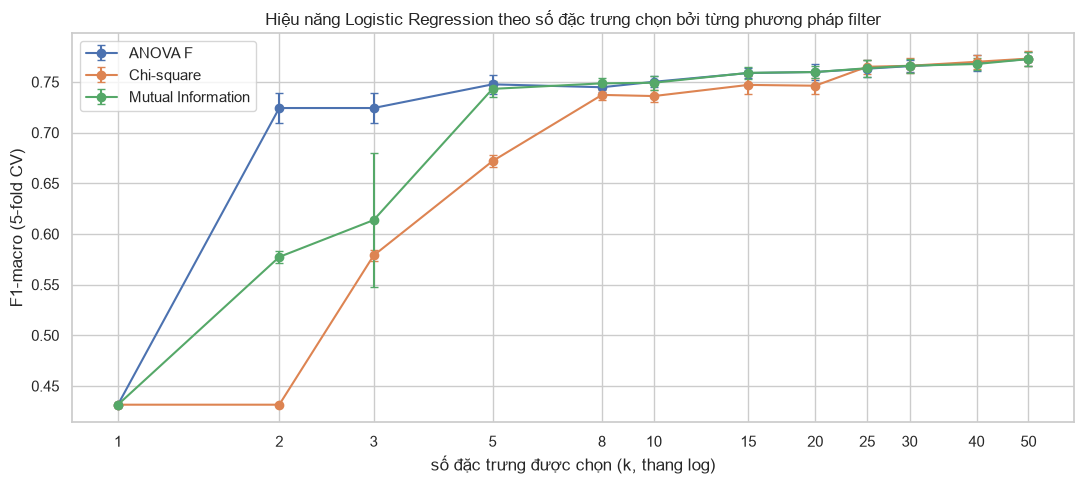

In [ ]:
def filter_scores(method: str, Xm: pd.DataFrame, yv) -> np.ndarray:
    if method == "ANOVA F":
        s = f_classif(Xm, yv)[0]
    elif method == "Chi-square":
        s = chi2(MinMaxScaler().fit_transform(Xm), yv)[0]  # chi2 đòi hỏi giá trị không âm
    else:
        s = mutual_info_classif(Xm, yv, discrete_features=discrete_mask, random_state=RANDOM_STATE)
    return np.nan_to_num(s, nan=-np.inf)


FILTERS = ["ANOVA F", "Chi-square", "Mutual Information"]
K_GRID = [k for k in [1, 2, 3, 5, 8, 10, 15, 20, 25, 30, 40, 50] if k < len(FEATURES)] + [len(FEATURES)]
curve_rows = []
t0 = time.perf_counter()
for fold, (tr, va) in enumerate(CV.split(X_fs_train, y_train)):
    X_tr_f, X_va_f, y_tr_f, y_va_f = X_fs_train.iloc[tr], X_fs_train.iloc[va], y_train.iloc[tr], y_train.iloc[va]
    for method in FILTERS:
        order = np.argsort(-filter_scores(method, X_tr_f, y_tr_f))
        for k in K_GRID:
            cols = X_fs_train.columns[order[:k]]
            lr = LogisticRegression(max_iter=3000).fit(X_tr_f[cols], y_tr_f)
            curve_rows.append({"phương pháp": method, "k": k, "fold": fold,
                               "F1": f1_score(y_va_f, lr.predict(X_va_f[cols]), average="macro")})
fs_curves = pd.DataFrame(curve_rows)
print(f"Thời gian chạy: {time.perf_counter() - t0:.1f}s")

fs_curve_summary = fs_curves.groupby(["phương pháp", "k"])["F1"].agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(11, 5))
for method, g in fs_curve_summary.groupby("phương pháp"):
    ax.errorbar(g["k"], g["mean"], yerr=g["std"], marker="o", capsize=3, label=method)
ax.set_xscale("log")
ax.set_xticks(K_GRID)
ax.set_xticklabels(K_GRID)
ax.set(xlabel="số đặc trưng được chọn (k, thang log)", ylabel="F1-macro (5-fold CV)",
       title="Hiệu năng Logistic Regression theo số đặc trưng chọn bởi từng phương pháp filter")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
TOLERANCE = 0.005  # chấp nhận kém hơn F1 tốt nhất tối đa 0.005 để đổi lấy mô hình gọn hơn
best_k_rows = []
for method, g in fs_curve_summary.groupby("phương pháp"):
    best = g["mean"].max()
    k_star = int(g.loc[g["mean"] >= best - TOLERANCE, "k"].min())
    best_k_rows.append({"phương pháp": method, "F1 tốt nhất": best, "k đạt F1 tốt nhất": int(g.loc[g["mean"].idxmax(), "k"]),
                        "k* (nhỏ nhất trong ngưỡng 0.005)": k_star,
                        "F1 tại k*": float(g.loc[g["k"] == k_star, "mean"].iloc[0])})
filter_best_k = pd.DataFrame(best_k_rows).set_index("phương pháp")
filter_best_k

,F1 tốt nhất,k đạt F1 tốt nhất,k* (nhỏ nhất trong ngưỡng 0.005),F1 tại k*
phương pháp,,,,
ANOVA F,0.7726,50,40,0.7688
Chi-square,0.7731,50,40,0.7699
Mutual Information,0.7726,50,40,0.7677


### Nhận xét chọn đặc trưng bằng filter

**Kết quả kiểm định:**

- **ANOVA:** 5/6 biến số có ý nghĩa rất mạnh. `education.num` dẫn đầu (F = 3.274), tiếp theo là `capital.gain` (F = 2.264). **`fnlwgt` không có ý nghĩa** (F = 1,07, p = 0,301), xác nhận nhận định từ EDA rằng đây là trọng số chọn mẫu, không phải đặc điểm cá nhân.
- **Chi-square:** mọi biến phân loại đều có ý nghĩa. Xếp hạng theo Cramér's V trùng với EDA: `relationship` (0,456), `marital.status` (0,449), `occupation` (0,354)...
- **MI:** `marital.status_Married-civ-spouse` dẫn đầu (0,106), tiếp theo là `capital.gain` (0,084). MI nắm được quan hệ phi tuyến của `capital.gain`: chỉ cần *có* lãi vốn là xác suất >50K đã tăng mạnh.

**Đường cong F1 theo $k$:**

- Với $k = 1$, F1 chỉ là 0,43, tức mô hình đoán tất cả là `≤50K`. Đặc trưng tốt nhất (`Married-civ-spouse`) chỉ nâng xác suất >50K lên khoảng 45%, vẫn dưới ngưỡng 0,5.
- **ANOVA đi lên nhanh nhất ở $k$ nhỏ** (0,725 với $k = 2$): ANOVA ưu tiên biến số liên tục như `education.num`. **Chi-square chậm nhất** (vẫn 0,43 ở $k = 2$, 0,58 ở $k = 3$): sau Min-Max, chi-square ưu tiên các cột One-Hot có tần suất lệch mạnh theo lớp, những cột riêng lẻ không đủ vượt ngưỡng 0,5. MI có phương sai lớn ở $k = 3$ (±0,07): đặc trưng thứ 3 thay đổi giữa các fold.
- **Từ $k \approx 8$ trở đi, ba đường cong gần như trùng nhau** và tăng chậm tới 0,773 ở $k = 50$. Phần lớn thông tin nằm trong khoảng 10 đặc trưng đầu; các đặc trưng còn lại chỉ đóng góp một chút.
- Với ngưỡng chấp nhận 0,005, cả ba phương pháp đều chọn $k^* = 40$. Đường cong rất phẳng trong khoảng 25–50, nên ranh giới chính xác không quá quan trọng.

Thời gian chạy: 12.8s
RFECV chọn 47 / 50 đặc trưng, F1 CV = 0.7731


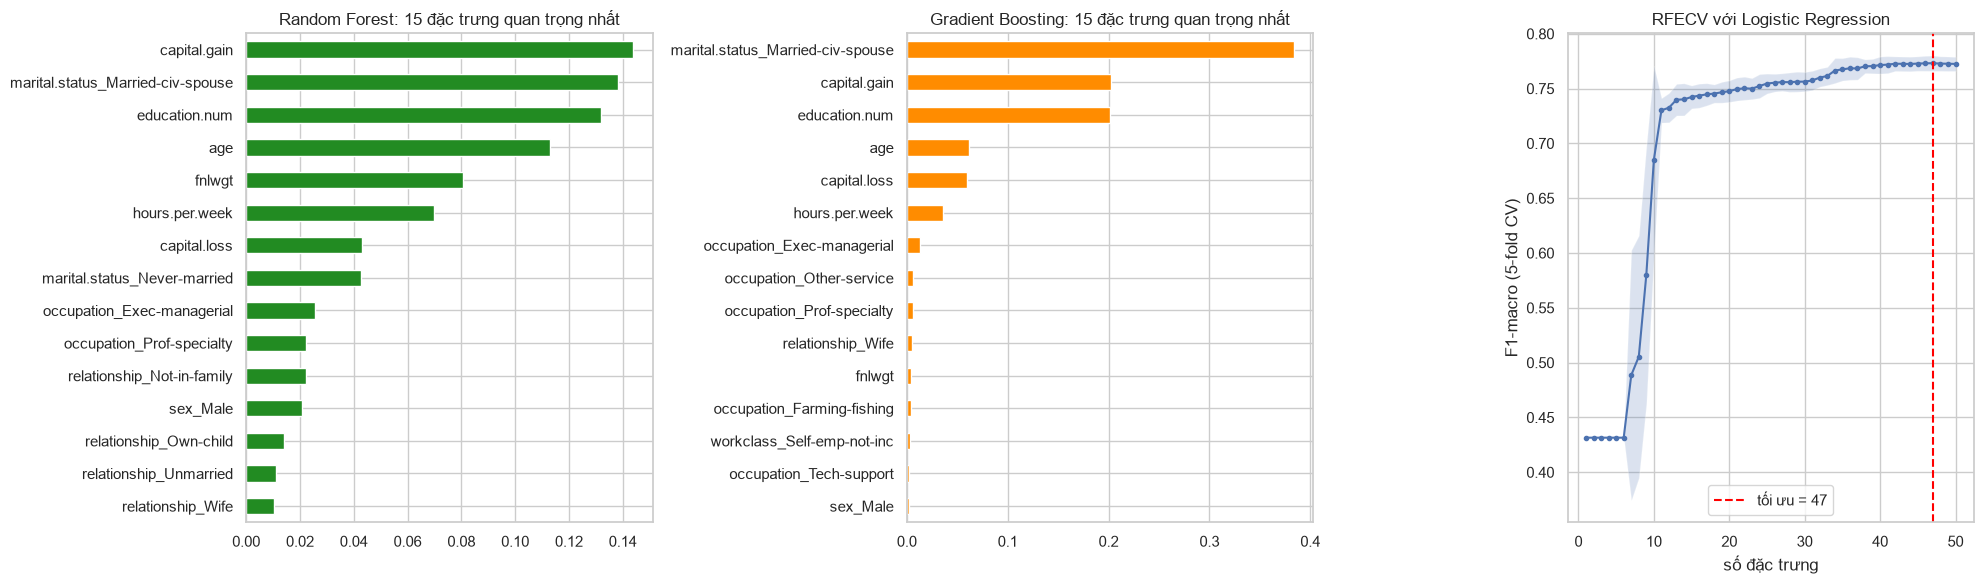

In [ ]:
t0 = time.perf_counter()
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE).fit(X_fs_train, y_train)
gb = GradientBoostingClassifier(random_state=RANDOM_STATE).fit(X_fs_train, y_train)
rf_importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
gb_importance = pd.Series(gb.feature_importances_, index=FEATURES).sort_values(ascending=False)

rfecv = RFECV(LogisticRegression(max_iter=3000), step=1, cv=CV, scoring="f1_macro", min_features_to_select=1, n_jobs=-1)
rfecv.fit(X_fs_train, y_train)
rfecv_selected = X_fs_train.columns[rfecv.support_].tolist()
print(f"Thời gian chạy: {time.perf_counter() - t0:.1f}s")
print(f"RFECV chọn {rfecv.n_features_} / {len(FEATURES)} đặc trưng, F1 CV = {rfecv.cv_results_['mean_test_score'].max():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
rf_importance.head(15).iloc[::-1].plot.barh(ax=axes[0], color="forestgreen")
axes[0].set_title("Random Forest: 15 đặc trưng quan trọng nhất")
gb_importance.head(15).iloc[::-1].plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("Gradient Boosting: 15 đặc trưng quan trọng nhất")
n_feats = rfecv.cv_results_["n_features"]
axes[2].plot(n_feats, rfecv.cv_results_["mean_test_score"], marker=".")
axes[2].fill_between(n_feats, rfecv.cv_results_["mean_test_score"] - rfecv.cv_results_["std_test_score"],
                     rfecv.cv_results_["mean_test_score"] + rfecv.cv_results_["std_test_score"], alpha=0.2)
axes[2].axvline(rfecv.n_features_, color="red", ls="--", label=f"tối ưu = {rfecv.n_features_}")
axes[2].set(xlabel="số đặc trưng", ylabel="F1-macro (5-fold CV)", title="RFECV với Logistic Regression")
axes[2].legend()
fig.tight_layout()
plt.show()

In [ ]:
rank_table = pd.DataFrame({
    "ANOVA F": pd.Series(f_classif(X_fs_train, y_train)[0], index=FEATURES).rank(ascending=False),
    "Chi-square": pd.Series(chi2(MinMaxScaler().fit_transform(X_fs_train), y_train)[0], index=FEATURES).rank(ascending=False),
    "MI": mi_scores.rank(ascending=False),
    "Random Forest": rf_importance.rank(ascending=False),
    "Gradient Boosting": gb_importance.rank(ascending=False),
})
rank_table["RFECV chọn"] = rank_table.index.isin(rfecv_selected)
rank_table["hạng TB"] = rank_table[["ANOVA F", "Chi-square", "MI", "Random Forest", "Gradient Boosting"]].mean(axis=1)
rank_table = rank_table.sort_values("hạng TB")
rank_corr = rank_table[["ANOVA F", "Chi-square", "MI", "Random Forest", "Gradient Boosting"]].corr(method="spearman")
display(rank_corr.round(3))
print("15 đặc trưng có hạng trung bình tốt nhất và 10 đặc trưng có hạng kém nhất:")
pd.concat([rank_table.head(15), rank_table.tail(10)])

,ANOVA F,Chi-square,MI,Random Forest,Gradient Boosting
ANOVA F,1.0000,0.8730,0.9110,0.7000,0.5210
Chi-square,0.8730,1.0000,0.7800,0.5540,0.4230
MI,0.9110,0.7800,1.0000,0.7850,0.5850
Random Forest,0.7000,0.5540,0.7850,1.0000,0.7300
Gradient Boosting,0.5210,0.4230,0.5850,0.7300,1.0000


15 đặc trưng có hạng trung bình tốt nhất và 10 đặc trưng có hạng kém nhất:


,ANOVA F,Chi-square,MI,Random Forest,Gradient Boosting,RFECV chọn,hạng TB
marital.status_Married-civ-spouse,1.0000,1.0000,1.0000,2.0000,1.0000,True,1.2000
capital.gain,4.0000,3.0000,2.0000,1.0000,2.0000,True,2.4000
education.num,2.0000,23.0000,3.0000,3.0000,3.0000,True,6.8000
occupation_Exec-managerial,9.0000,5.0000,12.0000,9.0000,7.0000,True,8.4000
age,6.0000,26.0000,4.0000,4.0000,4.0000,True,8.8000
capital.loss,14.0000,13.0000,7.0000,7.0000,5.0000,True,9.2000
occupation_Prof-specialty,10.0000,6.0000,14.0000,10.0000,9.0000,True,9.8000
hours.per.week,5.0000,29.0000,6.0000,6.0000,6.0000,True,10.4000
sex_Male,8.0000,11.0000,10.0000,12.0000,15.0000,True,11.2000
occupation_Other-service,12.0000,8.0000,13.0000,16.0000,8.0000,True,11.4000


### Chọn tập đặc trưng cuối cùng

Ta so sánh F1-macro CV của các ứng viên: toàn bộ đặc trưng, mỗi phương pháp filter tại $k^*$ của nó, và tập RFECV chọn. Chọn tập **ít đặc trưng nhất** có F1 không kém tập tốt nhất quá 0,005. Danh sách đặc trưng của các phương pháp filter được tính lại trên toàn bộ tập train.

In [ ]:
candidates = {"Tất cả đặc trưng": FEATURES, "RFECV": rfecv_selected}
for method in FILTERS:
    k_star = int(filter_best_k.loc[method, "k* (nhỏ nhất trong ngưỡng 0.005)"])
    order = np.argsort(-filter_scores(method, X_fs_train, y_train))
    candidates[f"{method} (k={k_star})"] = X_fs_train.columns[order[:k_star]].tolist()

cand_rows = []
for name, cols in candidates.items():
    s = cross_val_score(LogisticRegression(max_iter=3000), X_fs_train[cols], y_train, cv=CV, scoring="f1_macro", n_jobs=-1)
    cand_rows.append({"tập đặc trưng": name, "số đặc trưng": len(cols), "F1 CV": s.mean(), "F1 std": s.std()})
candidate_table = pd.DataFrame(cand_rows).set_index("tập đặc trưng").sort_values("số đặc trưng")
eligible = candidate_table[candidate_table["F1 CV"] >= candidate_table["F1 CV"].max() - TOLERANCE]
SELECTED_SET = eligible["số đặc trưng"].idxmin()
SELECTED_FEATURES = candidates[SELECTED_SET]
print(f"Tập được chọn: {SELECTED_SET} với {len(SELECTED_FEATURES)} đặc trưng")
print("Các đặc trưng bị loại:", sorted(set(FEATURES) - set(SELECTED_FEATURES)))
candidate_table

Tập được chọn: Chi-square (k=40) với 40 đặc trưng
Các đặc trưng bị loại: ['fnlwgt', 'marital.status_Married-AF-spouse', 'native.country_bit0', 'native.country_bit3', 'native.country_bit4', 'occupation_Armed-Forces', 'occupation_None', 'workclass_Never-worked', 'workclass_State-gov', 'workclass_Without-pay']


,số đặc trưng,F1 CV,F1 std
tập đặc trưng,,,
Chi-square (k=40),40,0.7703,0.0067
ANOVA F (k=40),40,0.7691,0.0063
Mutual Information (k=40),40,0.7681,0.0058
RFECV,47,0.7727,0.0064
Tất cả đặc trưng,50,0.7725,0.0064


### Nhận xét chọn đặc trưng dựa trên mô hình và tập cuối cùng

**Mức độ đồng thuận giữa các phương pháp** (tương quan Spearman giữa các bảng xếp hạng): ba phương pháp filter đồng thuận cao với nhau (0,78–0,91). Random Forest (0,55–0,79) và đặc biệt Gradient Boosting (0,42–0,59) xếp hạng khác hẳn.

- Mô hình cây đánh giá đặc trưng **trong ngữ cảnh** các đặc trưng khác. Ví dụ `marital.status_Never-married` đứng hạng 2–5 ở filter nhưng hạng 42 ở GB: khi đã biết `Married-civ-spouse`, thông tin về `Never-married` gần như dư thừa.
- `relationship_Own-child` (hạng 4–8 ở filter, hạng 28 ở GB) cũng dư thừa vì đã có `age`.
- Filter đánh giá từng đặc trưng **riêng lẻ** nên không thấy được sự dư thừa này.

**Các phương pháp đồng thuận về nhóm dẫn đầu:** `Married-civ-spouse`, `capital.gain`, `education.num`, `age`, `capital.loss`, `hours.per.week` và các nghề `Exec-managerial` / `Prof-specialty`. Nhóm cuối bảng gồm các mức rất hiếm (`Armed-Forces`, `Married-AF-spouse`, `Never-worked`, `None`, `Without-pay`).

**RFECV** giữ 47/50 đặc trưng (F1 0,7731). Đường cong RFECV phẳng từ khoảng 20 đặc trưng trở lên: Logistic Regression có regularization L2 mặc định nên tự giảm trọng số đặc trưng yếu, và việc loại thêm không giúp gì.

**Tập cuối cùng: Chi-square với $k = 40$** (F1 CV 0,7703, kém tập tốt nhất 0,0024 nhưng ít hơn 10 đặc trưng). Các đặc trưng bị loại đều có lý do rõ ràng:

- `fnlwgt`: không liên quan đến nhãn (ANOVA p = 0,30).
- `workclass_Never-worked` và `occupation_None`: cặp trùng lặp hoàn toàn đã phát hiện ở mục 4. Loại cả hai cũng **loại luôn VIF vô hạn**.
- Các mức cực hiếm như `Armed-Forces`, `Married-AF-spouse`, `Without-pay`, và 3 bit của `native.country`.

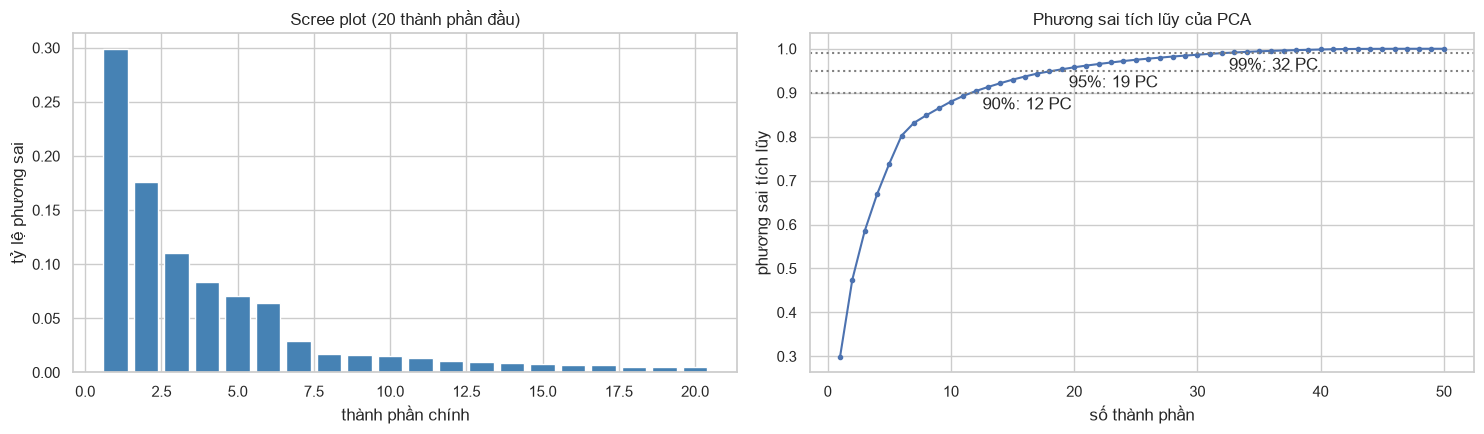

Số thành phần chính cần thiết: {'90%': 12, '95%': 19, '99%': 32} trên tổng 50 cột


In [ ]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_fs_train)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
pca_n = {t: int(np.searchsorted(cum_var, t) + 1) for t in (0.90, 0.95, 0.99)}

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].bar(range(1, 21), pca_full.explained_variance_ratio_[:20], color="steelblue")
ax[0].set(xlabel="thành phần chính", ylabel="tỷ lệ phương sai", title="Scree plot (20 thành phần đầu)")
ax[1].plot(range(1, len(cum_var) + 1), cum_var, marker=".")
for t, n in pca_n.items():
    ax[1].axhline(t, ls=":", color="gray")
    ax[1].annotate(f"{t:.0%}: {n} PC", (n, t), textcoords="offset points", xytext=(5, -12))
ax[1].set(xlabel="số thành phần", ylabel="phương sai tích lũy", title="Phương sai tích lũy của PCA")
fig.tight_layout()
plt.show()
print("Số thành phần chính cần thiết:", {f"{int(t*100)}%": n for t, n in pca_n.items()}, "trên tổng", X_fs_train.shape[1], "cột")

Thời gian tính 3 embedding: 743.9s


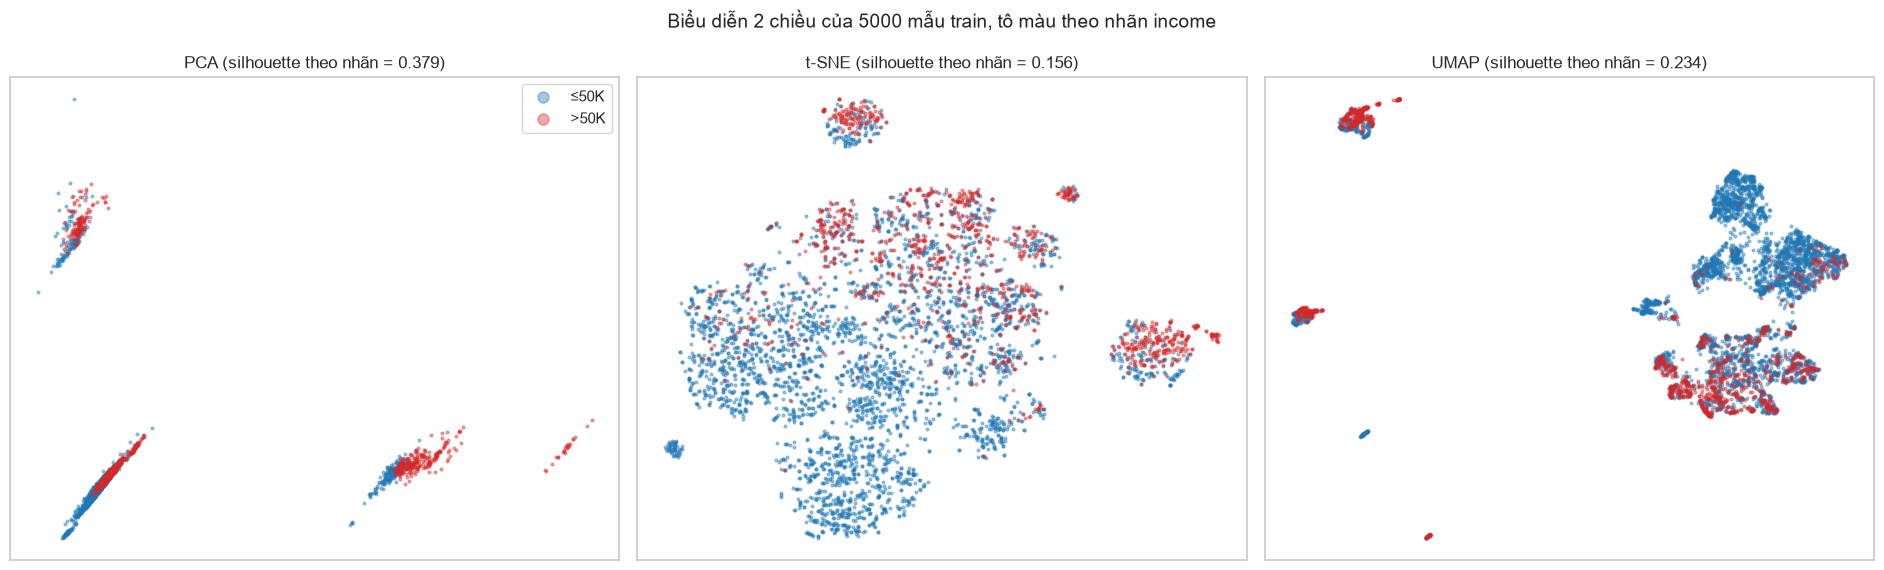

,silhouette theo nhãn
PCA,0.3786
t-SNE,0.1564
UMAP,0.2341
Không gian gốc,0.1375


In [ ]:
sample = X_fs_train.sample(n=5000, random_state=RANDOM_STATE)
y_sample = y_train.loc[sample.index].to_numpy()

t0 = time.perf_counter()
emb = {
    "PCA": PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(sample),
    "t-SNE": TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(sample),
    "UMAP": umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE, n_jobs=1).fit_transform(sample),
}
print(f"Thời gian tính 3 embedding: {time.perf_counter() - t0:.1f}s")
embedding_silhouette = {name: silhouette_score(E, y_sample) for name, E in emb.items()}
embedding_silhouette["Không gian gốc"] = silhouette_score(sample, y_sample)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
for ax, (name, E) in zip(axes, emb.items()):
    for label, color, text in [(0, "tab:blue", "≤50K"), (1, "tab:red", ">50K")]:
        sel = y_sample == label
        ax.scatter(E[sel, 0], E[sel, 1], s=4, alpha=0.4, c=color, label=text)
    ax.set_title(f"{name} (silhouette theo nhãn = {embedding_silhouette[name]:.3f})")
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].legend(markerscale=4)
fig.suptitle("Biểu diễn 2 chiều của 5000 mẫu train, tô màu theo nhãn income", fontsize=14)
fig.tight_layout()
plt.show()
pd.Series(embedding_silhouette, name="silhouette theo nhãn").to_frame()

### Nhận xét giảm chiều

**PCA:** 50 cột cần 12 thành phần để giải thích 90% phương sai, 19 thành phần cho 95% và 32 thành phần cho 99%. Scree plot không có "khuỷu" rõ ràng sau vài thành phần đầu: thông tin trải đều trên nhiều chiều, phù hợp với việc các biến gốc gần như độc lập. **Giảm chiều bằng PCA không mang lại lợi ích lớn cho bài toán này.**

**Biểu diễn 2 chiều:**

- **PCA 2D** tách thành vài cụm dài, chủ yếu theo `capital.gain` và `capital.loss`. Sau Quantile Transform, hai biến này có hai khối (bằng 0 và khác 0), tạo nên các cụm. Nhóm có lãi vốn (cụm bên phải) chủ yếu là >50K. Silhouette theo nhãn đạt 0,379, nhưng con số này phản ánh **cấu trúc cụm nhân tạo** của Quantile Transform nhiều hơn là khả năng phân tách hai lớp thật.
- **t-SNE** (0,156) và **UMAP** (0,234) cho thấy hai lớp **chồng lấn đáng kể** ở vùng trung tâm. Các cụm nhỏ tách riêng tương ứng với tổ hợp `capital.*` khác 0. UMAP gom các vùng >50K (đỏ) gọn hơn t-SNE.
- Silhouette trên không gian gốc 50 chiều chỉ là 0,138.

**Kết luận:** hai lớp **không phân tách tuyến tính rõ ràng**. Điều này giải thích vì sao F1 của Logistic Regression dừng ở khoảng 0,77, trong khi mô hình phi tuyến (HGB) đạt khoảng 0,81.

## 6. [Nâng cao] Xử lý mất cân bằng lớp

### Lý thuyết

Tỷ lệ nhãn là 76/24. Một mô hình luôn đoán `≤50K` đã đạt accuracy 76% mà không có ích gì, vì vậy ta đánh giá bằng:

$$\text{Precision} = \frac{TP}{TP + FP}, \quad \text{Recall} = \frac{TP}{TP + FN}, \quad F1 = \frac{2PR}{P + R}, \quad \text{F1-macro} = \frac{F1_{\text{lớp } 0} + F1_{\text{lớp } 1}}{2},$$

cùng với **AUC-ROC**, là diện tích dưới đường cong TPR theo FPR khi thay đổi ngưỡng quyết định. AUC không phụ thuộc vào ngưỡng. Precision và Recall được tính cho lớp thiểu số `>50K`.

| Kỹ thuật | Cách hoạt động |
|---|---|
| **SMOTE** | Với mỗi mẫu thiểu số $x_i$, chọn ngẫu nhiên một trong $k$ láng giềng thiểu số $x_{nn}$ rồi sinh mẫu mới $x_{\text{new}} = x_i + \lambda\,(x_{nn} - x_i)$, với $\lambda \sim U(0, 1)$ |
| **ADASYN** | Như SMOTE, nhưng sinh **nhiều mẫu hơn** quanh những mẫu thiểu số khó học: số mẫu sinh cho $x_i$ tỷ lệ với $r_i = \Delta_i / k$, trong đó $\Delta_i$ là số láng giềng thuộc lớp đa số |
| **Random Under-sampling** | Bỏ ngẫu nhiên các mẫu lớp đa số cho tới khi hai lớp cân bằng; nhanh nhưng làm mất thông tin |
| *class_weight = balanced* | Không đổi dữ liệu mà tăng trọng số mất mát của lớp thiểu số theo tỷ lệ $\frac{n}{2 n_c}$; dùng làm mốc so sánh |

**Vì sao không được resample trước khi chia train/test?**

- SMOTE sinh mẫu mới bằng nội suy giữa các điểm *gần nhau*. Nếu resample trước khi chia, một mẫu tổng hợp trong tập test có thể được nội suy từ chính các điểm trong tập train, hoặc ngược lại. Tập test khi đó chứa thông tin của tập train, và mô hình được chấm trên những điểm "gần như đã thấy". Kết quả bị **thổi phồng** (data leakage).
- Tập test còn mất đi **phân phối thật** (76/24) mà mô hình sẽ gặp khi triển khai, nên Precision đo được không còn phản ánh thực tế.
- Vì vậy, resampling chỉ được làm trên tập train. Khi dùng cross-validation, resampling phải nằm **bên trong** từng fold.

Phần cuối của mục này kiểm chứng điều trên bằng thực nghiệm.

In [ ]:
X_sel_train, X_sel_test = X_fs_train[SELECTED_FEATURES], X_fs_test[SELECTED_FEATURES]

SAMPLERS = {
    "Không xử lý": None,
    "class_weight=balanced": "weight",
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
    "ADASYN": ADASYN(random_state=RANDOM_STATE),
    "Random Under-sampling": RandomUnderSampler(random_state=RANDOM_STATE),
}


def make_model(name, balanced=False):
    cw = "balanced" if balanced else None
    if name == "LogReg":
        return LogisticRegression(max_iter=3000, class_weight=cw)
    return HistGradientBoostingClassifier(random_state=RANDOM_STATE, class_weight=cw)


def metrics(y_true, proba, thr=0.5) -> dict:
    pred = (proba >= thr).astype(int)
    return {"Precision": precision_score(y_true, pred), "Recall": recall_score(y_true, pred),
            "F1-macro": f1_score(y_true, pred, average="macro"), "AUC-ROC": roc_auc_score(y_true, proba)}


imb_rows, resampled_sizes = [], {}
for s_name, sampler in SAMPLERS.items():
    if sampler is None or sampler == "weight":
        X_rs, y_rs = X_sel_train, y_train
    else:
        X_rs, y_rs = sampler.fit_resample(X_sel_train, y_train)  # chỉ resample tập train
    resampled_sizes[s_name] = {"số mẫu": len(y_rs), "lớp 0": int((y_rs == 0).sum()), "lớp 1": int((y_rs == 1).sum())}
    for m_name in ("LogReg", "HGB"):
        model = make_model(m_name, balanced=(sampler == "weight")).fit(X_rs, y_rs)
        imb_rows.append({"kỹ thuật": s_name, "mô hình": m_name, **metrics(y_test, model.predict_proba(X_sel_test)[:, 1])})

imbalance_results = pd.DataFrame(imb_rows).set_index(["mô hình", "kỹ thuật"])
display(pd.DataFrame(resampled_sizes).T)
imbalance_results.round(4)

,số mẫu,lớp 0,lớp 1
Không xử lý,26029,19758,6271
class_weight=balanced,26029,19758,6271
SMOTE,39516,19758,19758
ADASYN,38387,19758,18629
Random Under-sampling,12542,6271,6271


,,Precision,Recall,F1-macro,AUC-ROC
mô hình,kỹ thuật,,,,
LogReg,Không xử lý,0.7111,0.5886,0.7718,0.8943
HGB,Không xử lý,0.7712,0.6429,0.8083,0.9214
LogReg,class_weight=balanced,0.5593,0.8246,0.7624,0.8946
HGB,class_weight=balanced,0.6073,0.8431,0.7936,0.9218
LogReg,SMOTE,0.5634,0.8189,0.7640,0.8941
HGB,SMOTE,0.6554,0.7557,0.7988,0.9109
LogReg,ADASYN,0.5256,0.8654,0.7460,0.8931
HGB,ADASYN,0.6294,0.7787,0.7920,0.9117
LogReg,Random Under-sampling,0.5567,0.8202,0.7602,0.8943


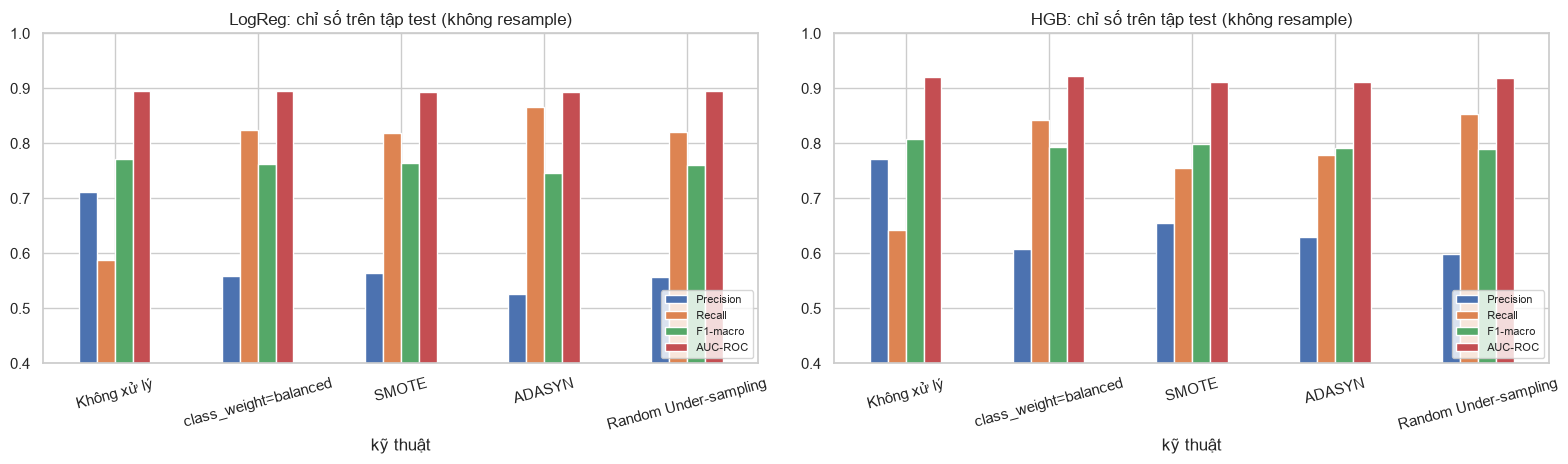

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, m_name in zip(axes, ("LogReg", "HGB")):
    imbalance_results.loc[m_name].plot.bar(ax=ax, rot=15)
    ax.set_ylim(0.4, 1.0)
    ax.set_title(f"{m_name}: chỉ số trên tập test (không resample)")
    ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

### Kiểm chứng: resample **trước** khi chia train/test

Ghép lại train và test, áp dụng SMOTE trên toàn bộ, rồi mới chia 80/20, và so sánh với cách làm đúng ở trên.

In [ ]:
X_all = pd.concat([X_sel_train, X_sel_test], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)
X_all_rs, y_all_rs = SMOTE(random_state=RANDOM_STATE).fit_resample(X_all, y_all)
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(X_all_rs, y_all_rs, test_size=0.2, stratify=y_all_rs, random_state=RANDOM_STATE)

wrong_rows = []
for m_name in ("LogReg", "HGB"):
    wrong = make_model(m_name).fit(Xw_tr, yw_tr)
    wrong_rows.append({"mô hình": m_name, "cách làm": "SAI: SMOTE trước khi chia",
                       **metrics(yw_te, wrong.predict_proba(Xw_te)[:, 1])})
    wrong_rows.append({"mô hình": m_name, "cách làm": "ĐÚNG: SMOTE chỉ trên train",
                       **imbalance_results.loc[(m_name, "SMOTE")].to_dict()})
leakage_smote = pd.DataFrame(wrong_rows).set_index(["mô hình", "cách làm"])
print(f"Tập test 'sai' có tỷ lệ lớp 1 = {yw_te.mean():.2%} (thực tế: {y_test.mean():.2%})")
leakage_smote.round(4)

Tập test 'sai' có tỷ lệ lớp 1 = 50.00% (thực tế: 24.09%)


Precision  Recall  F1-macro  AUC-ROC
mô hình cách làm                                                        
LogReg  SAI: SMOTE trước khi chia      0.7911  0.8484    0.8119   0.8964
        ĐÚNG: SMOTE chỉ trên train     0.5634  0.8189    0.7640   0.8941
HGB     SAI: SMOTE trước khi chia      0.8582  0.9142    0.8815   0.9579
        ĐÚNG: SMOTE chỉ trên train     0.6554  0.7557    0.7988   0.9109

### Nhận xét xử lý mất cân bằng

**1. Resampling đánh đổi Precision lấy Recall, không làm mô hình "giỏi" hơn.**

- Với HGB, Recall lớp >50K tăng từ 0,643 lên 0,756 (SMOTE), 0,779 (ADASYN), 0,854 (Under-sampling). Precision giảm từ 0,771 xuống còn 0,60–0,66.
- **AUC-ROC gần như không đổi hoặc giảm nhẹ** (0,921 → 0,911–0,919). AUC đo khả năng *xếp hạng* độc lập với ngưỡng, nên AUC không đổi nghĩa là resampling **không giúp mô hình phân biệt hai lớp tốt hơn**. Nó chỉ dịch chuyển ngưỡng quyết định về phía lớp thiểu số.
- `class_weight=balanced`, cách đơn giản nhất và không tạo dữ liệu giả, cho kết quả tương đương (HGB: Recall 0,843, AUC 0,922).

**2. F1-macro cao nhất thuộc về mô hình không xử lý** (HGB 0,808). Bộ dữ liệu chỉ mất cân bằng vừa phải (3,15 : 1), và F1-macro coi hai lớp quan trọng ngang nhau.

**Nên chọn kỹ thuật nào phụ thuộc vào chi phí sai lầm.** Nếu bỏ sót người thu nhập cao tốn kém hơn (ví dụ trong tiếp thị sản phẩm cao cấp), nên dùng `class_weight=balanced` hoặc Under-sampling để Recall lên khoảng 0,85. Nếu cần Precision cao, giữ nguyên dữ liệu.

**3. ADASYN kém nhất với Logistic Regression** (F1 0,746, Precision 0,526). ADASYN sinh nhiều mẫu ở *vùng biên* giữa hai lớp, đúng nơi hai lớp chồng lấn (thấy rõ trên t-SNE và UMAP). Ranh giới tuyến tính vì thế bị kéo lệch nhiều nhất. **SMOTE và ADASYN** còn nội suy trên các cột One-Hot, tạo ra giá trị như 0,37 cho một biến nhị phân, vốn không có ý nghĩa. SMOTENC là biến thể xử lý đúng cho dữ liệu hỗn hợp.

**4. Thực nghiệm resample trước khi chia xác nhận lý thuyết.** Làm sai cho HGB F1 = 0,882 và AUC = 0,958, so với 0,799 và 0,911 khi làm đúng. Đó là mức tăng **+0,083 F1 hoàn toàn ảo**, do hai nguyên nhân:

- Các mẫu tổng hợp trong tập test được nội suy từ các điểm thuộc tập train, nên mô hình thực chất được chấm trên dữ liệu "gần như đã thấy".
- Tập test có tỷ lệ 50/50 thay vì 24/76 như thực tế, làm Precision được thổi phồng (0,858 so với 0,655).

## 7. Lưu dữ liệu đã tiền xử lý

Ma trận đặc trưng cuối cùng (đã điền giá trị thiếu, scale, mã hóa và chọn đặc trưng) được lưu vào `data/processed/` để dùng lại ở chương báo cáo. Tập train **không** resample, vì resampling là một phần của bước huấn luyện chứ không phải của dữ liệu.

In [ ]:
X_sel_train.assign(income=y_train.to_numpy()).to_parquet(PROCESSED_DIR / "adult_train.parquet", index=False)
X_sel_test.assign(income=y_test.to_numpy()).to_parquet(PROCESSED_DIR / "adult_test.parquet", index=False)
print("Đã lưu:", [p.name for p in sorted(PROCESSED_DIR.glob("adult_*.parquet"))])
print("Kích thước train/test:", X_sel_train.shape, X_sel_test.shape)

Đã lưu: ['adult_test.parquet', 'adult_train.parquet']
Kích thước train/test: (26029, 40) (6508, 40)


## 8. Tổng kết pipeline tiền xử lý dữ liệu bảng

| Bước | Lựa chọn cuối cùng | Căn cứ |
|---|---|---|
| Làm sạch | Loại 24 dòng trùng lặp; loại `education`; gán `occupation = None` cho `Never-worked` | EDA: trùng lặp; Spearman = 1 giữa `education` và `education.num`; thiếu cấu trúc |
| Chia dữ liệu | 80/20 có phân tầng, **trước mọi phép biến đổi học tham số** | Chống rò rỉ dữ liệu |
| Điền giá trị thiếu | `workclass`: Mode; `occupation`, `native.country`: kNN (k=10); thêm chỉ báo `work.missing`. Biến số (nếu có): MICE | Accuracy thí nghiệm B; NRMSE thí nghiệm A (MICE 0,941); cơ chế MAR |
| Ngoại lai | **Không loại** | Loại theo IQR, Z-score, IForest làm F1 giảm tới 0,054; ngoại lai là giá trị thật và có thông tin |
| Chuẩn hóa | Quantile Transform (output chuẩn) | kNN F1 cao nhất trong các phương án không suy biến; Robust bị loại vì IQR = 0 ở `capital.*` |
| Mã hóa | One-Hot (drop first) + Binary cho `native.country` | LogReg F1 ngang One-Hot đầy đủ với ít hơn 40% số cột; không rò rỉ nhãn |
| Chọn đặc trưng | Chi-square, giữ 40/50 đặc trưng | F1 chỉ kém tập tốt nhất 0,0024; loại `fnlwgt`, cặp cột trùng lặp và các mức hiếm |
| Mất cân bằng | Không resample dữ liệu đã lưu. Khi cần Recall cao, dùng `class_weight=balanced` khi huấn luyện | AUC không cải thiện khi resample; resample chỉ dịch ngưỡng quyết định |

**Các bài học chính:**

1. **Một lựa chọn hợp lý về lý thuyết cần được kiểm chứng bằng số.** Kế hoạch scale theo từng cột từ EDA nghe hợp lý nhưng cho kNN kém nhất. Robust Scaling có F1 cao nhất nhưng là do suy biến.
2. **Không có phương pháp tốt nhất cho mọi mô hình.** Quantile tốt cho kNN nhưng kém Z-score với Logistic Regression. Ordinal Encoding tệ với Logistic Regression nhưng tốt với HGB.
3. **"Ngoại lai" và "dữ liệu thiếu" đều có thể mang thông tin.** Người có lãi vốn và người bỏ trống nghề nghiệp đều liên hệ mạnh với nhãn. Xóa họ đi hay điền giá trị một cách máy móc đều làm mất tín hiệu.
4. **Rò rỉ dữ liệu tạo ra kết quả đẹp nhưng sai:** Target Encoding không cross-fitting (F1 0,89 trên train, 0,60 trên test), SMOTE trước khi chia (+0,08 F1 ảo).